<a href="https://colab.research.google.com/github/weichen642/26fall-datman/blob/main/PS5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Digital public-service demand and responsiveness

## PS0

How do public-service demand and reported responsiveness vary over time in Guangzhou 12345 and Hong Kong 1823? As an exploratory extension, how does Hong Kong hotline demand vary alongside rainfall?

This project examines smart-city governance, public value, and community resilience in the Pearl River Delta. This assignment develops the data-management component of describetives service demand and administrative indicators.

In [ ]:
# Data processing
import pandas as pd
import json
import re

In [ ]:
# File and web access
from pathlib import Path
from io import StringIO
from urllib.request import Request, urlopen
from urllib.error import URLError

In [ ]:
# Utility tools
import hashlib

from html import unescape
from datetime import datetime, timezone
from concurrent.futures import ThreadPoolExecutor
from IPython.display import display

In [ ]:
# Project settings

USE_CACHE = False

START, END = '2023-07', '2026-02'

In [ ]:
# Create folder for raw data

RAW = Path('raw')

RAW.mkdir(exist_ok=True)

In [ ]:
# Store download records

ledger = []

In [ ]:
def download(url, filename):
    # Set the local file path
    path = RAW / filename

    # Read from local cache if enabled
    if USE_CACHE:
        content = path.read_bytes()
        mode = 'explicit cache replay'

    # Otherwise, download from the Internet
    else:
        request = Request(url, headers={'User-Agent': 'Mozilla/5.0 academic coursework'})

        # Retry up to 3 times if the download fails
        for attempt in range(3):
            try:
                with urlopen(request, timeout=30) as response:
                    content = response.read()
                break
            except (URLError, TimeoutError) as exc:
                if attempt == 2:
                    raise RuntimeError('Download failed after 3 attempts: ' + url) from exc
                print('Retrying:', filename, 'attempt', attempt + 2)

        # Save the downloaded file locally
        path.write_bytes(content)
        mode = 'Internet'

    # Record download information for reproducibility
    ledger.append({'url': url, 'file': filename, 'mode': mode, 'run_time_utc': datetime.now(timezone.utc).isoformat(), 'sha256': hashlib.sha256(content).hexdigest()})

    # Return the file content as text
    return content.decode('utf-8-sig')

In [ ]:
GZ_URLS = ['https://www.gz.gov.cn/gz12345/dataDeclare/dataDeclareDetail.do?id=5703baa6-367f-11ee-83cf-38adbed808fb', 'https://www.gz.gov.cn/gz12345/dataDeclare/dataDeclareDetail.do?id=fc86f701-5067-11ee-83cf-38adbed808fb', 'https://www.gz.gov.cn/gz12345/dataDeclare/dataDeclareDetail.do?id=1aaa8f2d-9991-11ee-83cf-38adbed808fb', 'https://www.gz.gov.cn/gz12345/dataDeclare/dataDeclareDetail.do?id=5bb8d49d-fb92-11ee-b12e-38adbed808fb', 'https://www.gz.gov.cn/gz12345/dataDeclare/dataDeclareDetail.do?id=f1e5a50e-173e-11ef-b12e-38adbed808fb', 'https://www.gz.gov.cn/gz12345/dataDeclare/dataDeclareDetail.do?id=e662460c-5ac7-11ef-b12e-38adbed808fb', 'https://www.gz.gov.cn/gz12345/dataDeclare/dataDeclareDetail.do?id=e69f6e38-6fdc-11ef-b12e-38adbed808fb', 'https://www.gz.gov.cn/gz12345/dataDeclare/dataDeclareDetail.do?id=db89d4bb-8f8e-11ef-b12e-38adbed808fb', 'https://www.gz.gov.cn/gz12345/dataDeclare/dataDeclareDetail.do?id=b6af19cf-a65b-11ef-b12e-38adbed808fb', 'https://www.gz.gov.cn/gz12345/dataDeclare/dataDeclareDetail.do?id=52119323-bc45-11ef-b12e-38adbed808fb', 'https://www.gz.gov.cn/gz12345/dataDeclare/dataDeclareDetail.do?id=1b84de85-d256-11ef-b12e-38adbed808fb', 'https://www.gz.gov.cn/gz12345/dataDeclare/dataDeclareDetail.do?id=56583d60-4b26-11f0-b12e-38adbed808fb', 'https://www.gz.gov.cn/gz12345/dataDeclare/dataDeclareDetail.do?id=74b87dfe-4b26-11f0-b12e-38adbed808fb', 'https://www.gz.gov.cn/gz12345/dataDeclare/dataDeclareDetail.do?id=95f72143-4b26-11f0-b12e-38adbed808fb', 'https://www.gz.gov.cn/gz12345/dataDeclare/dataDeclareDetail.do?id=4e6ebc42-5ade-11f0-b12e-38adbed808fb', 'https://www.gz.gov.cn/gz12345/dataDeclare/dataDeclareDetail.do?id=f6379bd4-726c-11f0-b12e-38adbed808fb', 'https://www.gz.gov.cn/gz12345/dataDeclare/dataDeclareDetail.do?id=03e3c66f-8c5b-11f0-b12e-38adbed808fb', 'https://www.gz.gov.cn/gz12345/dataDeclare/dataDeclareDetail.do?id=3c97eb73-a961-11f0-b12e-38adbed808fb', 'https://www.gz.gov.cn/gz12345/dataDeclare/dataDeclareDetail.do?id=f33e21b1-c5ef-11f0-b12e-38adbed808fb', 'https://www.gz.gov.cn/gz12345/dataDeclare/dataDeclareDetail.do?id=e5e63c4b-d410-11f0-b12e-38adbed808fb', 'https://www.gz.gov.cn/gz12345/dataDeclare/dataDeclareDetail.do?id=fd4ee1b8-ec5d-11f0-b12e-38adbed808fb', 'https://www.gz.gov.cn/gz12345/dataDeclare/dataDeclareDetail.do?id=091e277b-1447-11f1-b12e-38adbed808fb', 'https://www.gz.gov.cn/gz12345/dataDeclare/dataDeclareDetail.do?id=9dd83a01-229b-11f1-b12e-38adbed808fb']

# Download all Guangzhou monthly reports in parallel
def read_gz_raw(url):
    page_id = url.split('id=')[1]
    html = download(url, 'gz_' + page_id + '.html')
    return {'url': url, 'page_id': page_id, 'html': html}

with ThreadPoolExecutor(max_workers=4) as pool:
    gz_raw = list(pool.map(read_gz_raw, GZ_URLS))

print('Downloaded reports:', len(gz_raw))

print(gz_raw[0]['html'][:3000])

Downloaded reports: 23
<!DOCTYPE html PUBLIC "-//W3C//DTD XHTML 1.0 Transitional//EN" "http://www.w3.org/TR/xhtml1/DTD/xhtml1-transitional.dtd">
<html xmlns="http://www.w3.org/1999/xhtml">
<head>
    <meta http-equiv="Content-Type" content="text/html; charset=utf-8"/>
    <link href="http://www.gz.gov.cn/xhtml/images/favicon.ico" rel="shortcut icon" type="image/x-icon"/>
    <title>广州12345政务服务便民热线</title>
    <meta name="SiteName" content="广州市人民政府门户网站">
<meta name="SiteDomain" content="www.gz.gov.cn">
<meta name="SiteIDCode" content="4401000004">
<meta name="ColumnName" content="广州12345政务服务便民热线栏目">
<meta name="ColumnType" content="咨询投诉">
<meta name="ColumnDescription" content=广州12345政务服务便民热线是广州市人民政府设立，整合全市各类非紧急类政府服务专线，以便民、智能、高效为服务理念，为公众提供政务咨询、民生诉求、政民互动、投诉举报、效能监察等公共服务，提高城市治理法治化、精准化、智能化、专业化水平。">
<meta name="ColumnKeywords" content="广州12345政务服务便民热线">
 <meta name="PubDate" content="2019-01-01 00:00:00">
	<meta name="Author" content="">
	<meta name="ContentSource" content="广州12345政务服务便民热线">

In [ ]:
def clean_html(html: str) -> str:
    # Convert webpage HTML into plain text
    html = re.sub(r"<script[\s\S]*?</script>", " ", html, flags=re.I)
    html = re.sub(r"<style[\s\S]*?</style>", " ", html, flags=re.I)
    text = re.sub(r"<[^>]+>", "\n", html)
    text = unescape(text)
    text = re.sub(r"[ \t\r\f\v]+", " ", text)
    text = re.sub(r"\n\s*", "\n", text)
    return text.strip()

In [ ]:
# Clean all Guangzhou reports
for item in gz_raw:
    item['text'] = clean_html(item['html'])

print(gz_raw[0]['text'][:3000])

广州12345政务服务便民热线
无障碍
长者助手
微信
小程序
广州12345政务服务便民热线
我要诉求
自助下单
在线客服
领导接电
我要查询
知识库
案例公开
数据播报
关于热线
登录
您现在的位置：
广州12345政务服务便民热线
>
数据播报
>
数据播报详情
2023年7月，广州12345政务服务便民热线市民来电办理情况
2023-08-09 14:38:24
来源：广州12345政务服务便民热线
分享至：
微信扫一扫：分享
扫一扫，分享给好友或朋友圈
打印
2023年7月，热线共接到市民来电1247677次。应办转派工单382319件（含电话，微信，网页等），按时办结率99.84%，咨询类工单平均处理时长0天18时，非咨询类工单平均办理时长5天1时，市民满意率72.78%。
11个区承办工单量从多到少分别是：白云区（30827），天河区（26489），番禺区（20494），海珠区（15520），黄埔区（12482），增城区（12217），花都区（11671），越秀区（11261），荔湾区（11112），南沙区（9158），从化区（2660）。
承办工单量前十的市属部门分别是：市公安局（28313），市医保局（9268），市公积金中心（5045），市交通局（4576），市邮政管理局（2976），市税务局（2936），市人社局（1610），市市场监管局（1584），市卫健委（1561），市供电局（1382）。
工单量前十的问题类型分别是：人社类（39339），城管类（35205），消费维权（31954），公安事项（29072），住建类（19596），交通类（10654），环保类（10338），公共类（8722），教育类（7781），市场监管类（6336）。


In [ ]:
def parse_duration_days(value):
    # Convert both "X天X时" and "X.XX天" into days
    m = re.match(r'(\d+(?:\.\d+)?)天(?:(\d+(?:\.\d+)?)时)?', value)
    if m:
        return float(m.group(1)) + float(m.group(2) or 0) / 24
    return None

In [ ]:
def parse_pairs(segment):
    # Convert "name(count)" text into structured name-count pairs
    pairs = re.findall(r'([^，、（）\(\)]+)[（(](\d+)[）)]', segment)
    return [{'name': name.strip(), 'count': int(count)} for name, count in pairs]

In [ ]:
def parse_page(text, url, page_id):
    # Extract basic report information
    title = re.search(r'(\d{4})年(\d{1,2})月，广州12345政务服务便民热线市民来电办理情况', text)
    publish = re.search(r'(\d{4}-\d{2}-\d{2} \d{2}:\d{2}:\d{2})', text)

    main = {
        'id': page_id,
        'url': url,
        'year': int(title.group(1)) if title else None,
        'month': int(title.group(2)) if title else None,
        'period': f'{title.group(1)}-{int(title.group(2)):02d}' if title else None,
        'published_at': publish.group(1) if publish else None
    }

    # Extract main service indicators
    m = re.search(r'热线共接到市民来电(\d+)(?:次|通)', text)
    main['calls'] = int(m.group(1)) if m else None

    m = re.search(r'应办转派工单(\d+)件', text)
    main['transferred_work_orders'] = int(m.group(1)) if m else None

    m = re.search(r'按时办结率(\d+(?:\.\d+)?)%', text)
    main['on_time_completion_rate_pct'] = float(m.group(1)) if m else None

    m = re.search(r'咨询类工单平均处理时长([0-9.]+天(?:[0-9.]+时)?)', text)
    main['consultation_avg_days'] = parse_duration_days(m.group(1)) if m else None

    m = re.search(r'非咨询类工单平均办理时长([0-9.]+天(?:[0-9.]+时)?)', text)
    main['non_consultation_avg_days'] = parse_duration_days(m.group(1)) if m else None

    m = re.search(r'市民满意率(\d+(?:\.\d+)?)%', text)
    main['citizen_satisfaction_pct'] = float(m.group(1)) if m else None

    # Extract district, department, and issue-type rankings
    m = re.search(r'11个区承办工单量从多到少分别是：(.+?)(?:\n|承办工单量前十)', text, flags=re.S)
    districts = parse_pairs(m.group(1)) if m else []

    m = re.search(r'承办工单量前十的市属部门分别是：(.+?)(?:\n|工单量前十)', text, flags=re.S)
    departments = parse_pairs(m.group(1)) if m else []

    m = re.search(r'工单量前十的问题类型分别是：(.+?)(?:\n|$)', text, flags=re.S)
    issue_types = parse_pairs(m.group(1)) if m else []

    return main, districts, departments, issue_types


main, districts, departments, issue_types = parse_page(text=gz_raw[0]['text'], url=gz_raw[0]['url'], page_id=gz_raw[0]['page_id'])

print(main)
print(districts[:3])
print(departments[:3])
print(issue_types[:3])

{'id': '5703baa6-367f-11ee-83cf-38adbed808fb', 'url': 'https://www.gz.gov.cn/gz12345/dataDeclare/dataDeclareDetail.do?id=5703baa6-367f-11ee-83cf-38adbed808fb', 'year': 2023, 'month': 7, 'period': '2023-07', 'published_at': '2023-08-09 14:38:24', 'calls': 1247677, 'transferred_work_orders': 382319, 'on_time_completion_rate_pct': 99.84, 'consultation_avg_days': 0.75, 'non_consultation_avg_days': 5.041666666666667, 'citizen_satisfaction_pct': 72.78}
[{'name': '白云区', 'count': 30827}, {'name': '天河区', 'count': 26489}, {'name': '番禺区', 'count': 20494}]
[{'name': '市公安局', 'count': 28313}, {'name': '市医保局', 'count': 9268}, {'name': '市公积金中心', 'count': 5045}]
[{'name': '人社类', 'count': 39339}, {'name': '城管类', 'count': 35205}, {'name': '消费维权', 'count': 31954}]


In [ ]:
# Parse all Guangzhou monthly reports
gz_rows = []

for item in gz_raw:
    row, districts, departments, issues = parse_page(item['text'], item['url'], item['page_id'])
    gz_rows.append(row)

gz = pd.DataFrame(gz_rows)

# Check the parsed data
print('Parsed reports:', len(gz))
display(gz.head())

Parsed reports: 23


,id,url,year,month,period,published_at,calls,transferred_work_orders,on_time_completion_rate_pct,consultation_avg_days,non_consultation_avg_days,citizen_satisfaction_pct
0,5703baa6-367f-11ee-83cf-38adbed808fb,https://www.gz.gov.cn/gz12345/dataDeclare/data...,2023,7,2023-07,2023-08-09 14:38:24,1247677,382319,99.84,0.750000,5.041667,72.78
1,fc86f701-5067-11ee-83cf-38adbed808fb,https://www.gz.gov.cn/gz12345/dataDeclare/data...,2023,8,2023-08,2023-09-11 13:56:44,1225275,387648,99.79,0.791667,4.916667,72.07
2,1aaa8f2d-9991-11ee-83cf-38adbed808fb,https://www.gz.gov.cn/gz12345/dataDeclare/data...,2023,11,2023-11,2023-12-13 16:24:59,1205816,400961,99.85,0.750000,4.708333,70.39
3,5bb8d49d-fb92-11ee-b12e-38adbed808fb,https://www.gz.gov.cn/gz12345/dataDeclare/data...,2024,3,2024-03,2024-04-16 09:40:51,1266073,417042,99.89,0.670000,4.400000,75.27
4,f1e5a50e-173e-11ef-b12e-38adbed808fb,https://www.gz.gov.cn/gz12345/dataDeclare/data...,2024,4,2024-04,2024-05-21 14:54:18,1245652,414519,99.87,0.720000,4.740000,72.36


In [ ]:
# Format and sort the monthly data
gz['period'] = pd.PeriodIndex(gz['period'], freq='M')
gz = gz.sort_values('period').reset_index(drop=True)

# Check the time range
print('First month:', gz['period'].min())
print('Last month:', gz['period'].max())
display(gz[['period', 'calls']].head())

First month: 2023-07
Last month: 2026-02


,period,calls
0,2023-07,1247677
1,2023-08,1225275
2,2023-11,1205816
3,2024-03,1266073
4,2024-04,1245652


In [ ]:
# Check Guangzhou data completeness
assert not gz['period'].duplicated().any()
assert gz['period'].between(pd.Period(START), pd.Period(END)).all()

expected = pd.period_range(START, END, freq='M')
missing_months = expected.difference(gz['period'])

print('Observed months:', len(gz), 'of', len(expected))
print('Missing months:', list(missing_months))

Observed months: 23 of 32
Missing months: [Period('2023-09', 'M'), Period('2023-10', 'M'), Period('2023-12', 'M'), Period('2024-01', 'M'), Period('2024-02', 'M'), Period('2024-05', 'M'), Period('2024-06', 'M'), Period('2025-02', 'M'), Period('2025-04', 'M')]


In [ ]:
display(gz[['period', 'calls', 'transferred_work_orders',
            'non_consultation_avg_days', 'citizen_satisfaction_pct']].head())

,period,calls,transferred_work_orders,non_consultation_avg_days,citizen_satisfaction_pct
0,2023-07,1247677,382319,5.041667,72.78
1,2023-08,1225275,387648,4.916667,72.07
2,2023-11,1205816,400961,4.708333,70.39
3,2024-03,1266073,417042,4.400000,75.27
4,2024-04,1245652,414519,4.740000,72.36


In [ ]:
metrics = ['calls', 'transferred_work_orders', 'on_time_completion_rate_pct',
           'consultation_avg_days', 'non_consultation_avg_days', 'citizen_satisfaction_pct']
display(gz[metrics].describe().T.round(3))
display(gz[metrics].isna().sum().rename('missing'))
print(f"Across the {len(gz)} observed months, mean monthly calls were {gz.calls.mean():,.0f}.")
print(f"Mean monthly non-consultation case duration was {gz.non_consultation_avg_days.mean():.2f} days.")
print(f"The unweighted mean of published monthly satisfaction rates was {gz.citizen_satisfaction_pct.mean():.2f}%.")

,count,mean,std,min,25%,50%,75%,max
calls,23.0,1124633.174,140999.761,674099.00,1056724.000,1136254.00,1220581.500,1323374.00
transferred_work_orders,23.0,414988.087,42243.694,263578.00,414445.000,420969.00,434469.000,481033.00
on_time_completion_rate_pct,23.0,99.834,0.060,99.69,99.790,99.84,99.885,99.95
consultation_avg_days,23.0,0.777,0.274,0.59,0.630,0.72,0.760,1.78
non_consultation_avg_days,23.0,5.294,0.602,4.40,4.918,5.06,5.740,6.88
citizen_satisfaction_pct,23.0,71.197,8.472,64.17,67.230,68.73,71.460,96.85


,missing
calls,0
transferred_work_orders,0
on_time_completion_rate_pct,0
consultation_avg_days,0
non_consultation_avg_days,0
citizen_satisfaction_pct,0


Across the 23 observed months, mean monthly calls were 1,124,633.
Mean monthly non-consultation case duration was 5.29 days.
The unweighted mean of published monthly satisfaction rates was 71.20%.


<Axes: >

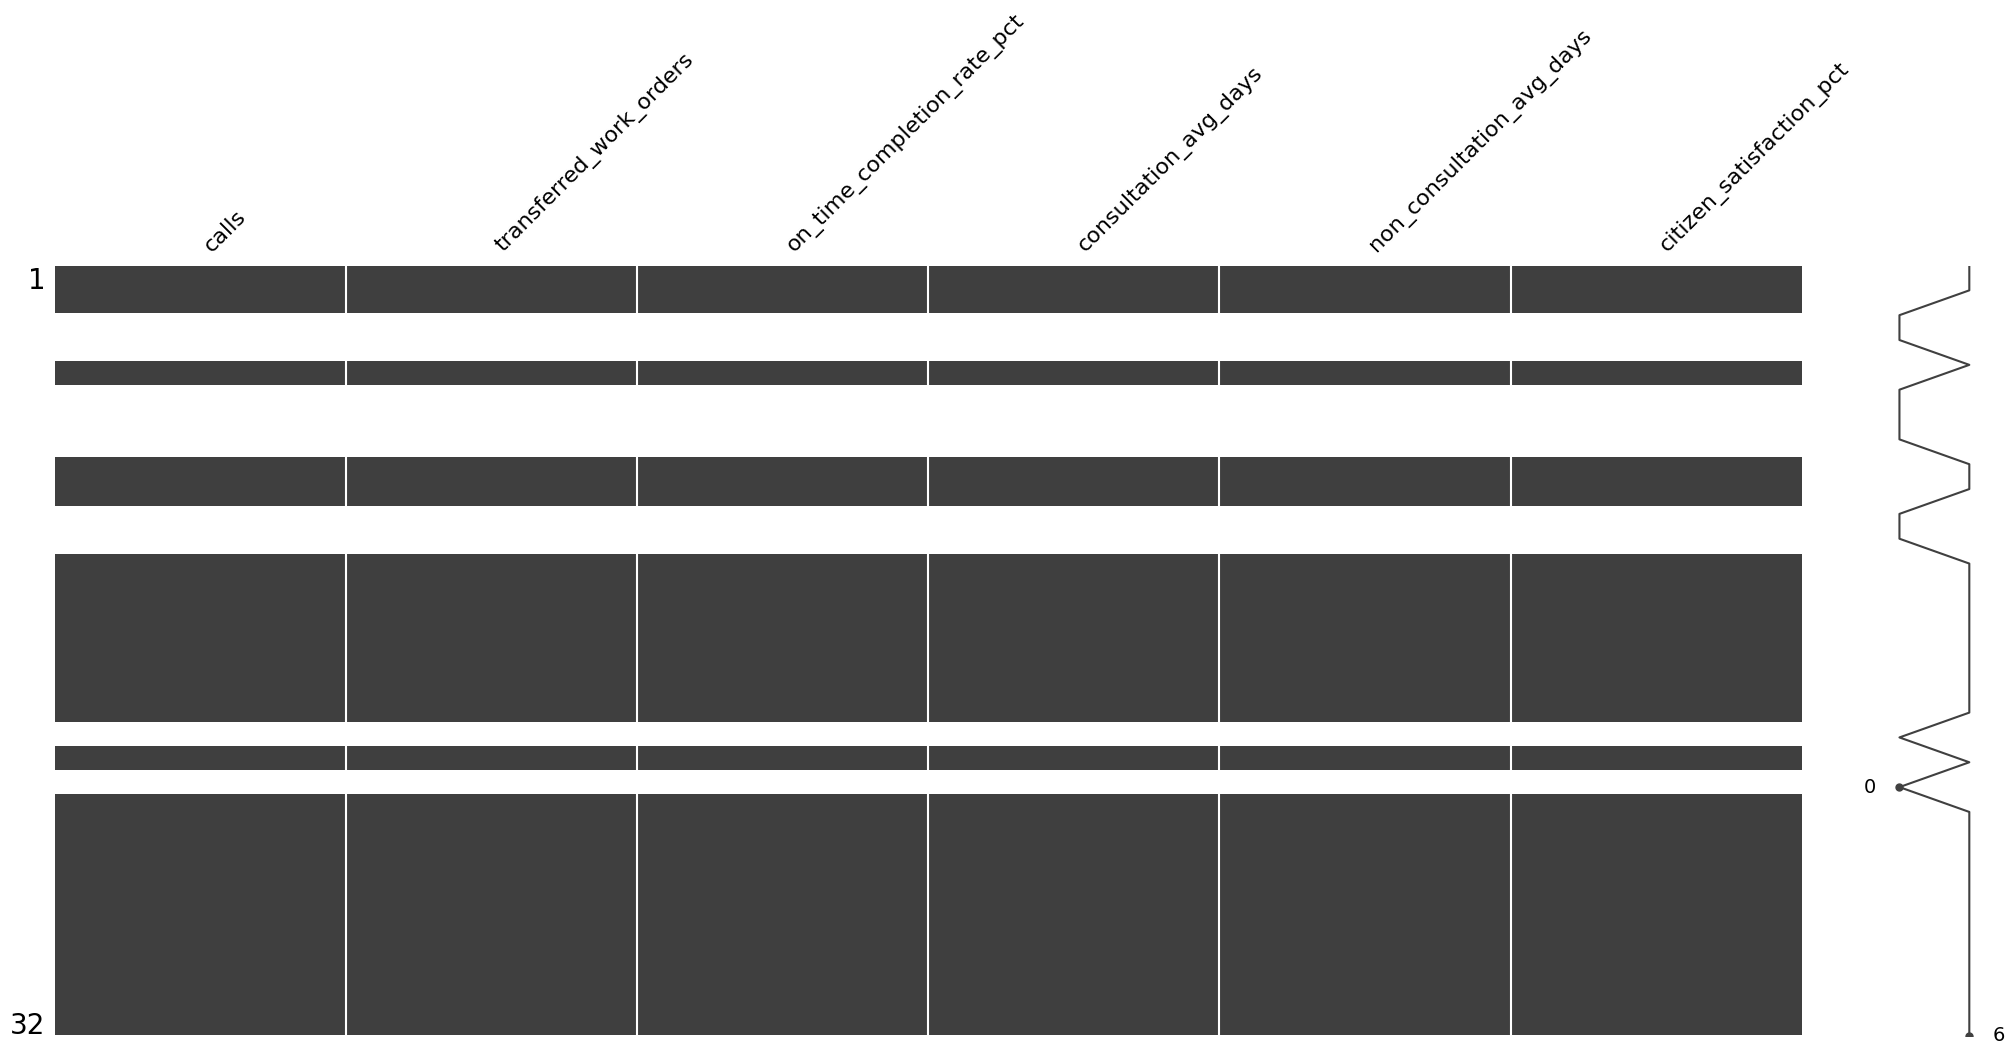

In [ ]:
# Visualize missing data
import missingno as msno

cols = ['calls', 'transferred_work_orders', 'on_time_completion_rate_pct',
        'consultation_avg_days', 'non_consultation_avg_days', 'citizen_satisfaction_pct']

gz_missing = gz.set_index('period')[cols].reindex(expected)

msno.matrix(gz_missing)

## PS1

PS1 examines monthly activity and responsiveness in Hong Kong's 1823 public service hotline, focusing on call volume, abandoned calls, call handling time, and the share of abandoned calls.

The analysis then links the hotline data with monthly rainfall measured at the Hong Kong Observatory and compares hotline activity between months with rainfall above and at or below the sample median.

In [ ]:
# Download Hong Kong 1823 data
HK_URL = 'https://www.1823.gov.hk/datagovhk/statistics/1823_statistic.json'
hk_raw = json.loads(download(HK_URL, 'hk1823.json'))

# Inspect the raw data
print('Number of records:', len(hk_raw))
print(hk_raw[0])

Number of records: 93
{'Date': {'Year': '2019', 'Month': 'Jan'}, 'No._of_calls_received': '364610', 'No._of_abandoned_calls': '22073', '%_of_calls_answered_within_12seconds': '65%', 'Average_call_handling_time(seconds)': '400', 'No._of_non_voice': {'No._of_emails': '28771', 'No._of_faxes': '686', 'No._of_Apps-inbound': '16042', 'No._of_SMS': '2274', 'No._of_web-inbound': '4459'}, 'Unique_page_view_1823_web': '293109', ' Enquiries': {'Call': '164732', 'Email': '2594', 'Fax': '50', 'Apps': '794', 'Chatbot': '', 'Voicebot': '', 'SMS': '198', 'Web': '466'}, 'ServiceRequestORComplaints': {'Call': '26397', 'Email': '5289', 'Fax': '318', 'Apps': '10952', 'Voicebot': '', 'SMS': '141', 'Web': '2958'}, ' Suggestions': {'Call': '567', 'Email': '79', 'Fax': '3', 'Apps': '71', 'SMS': '0', 'Web': '20'}, ' Compliments': {'Call': '53', 'Email': '22', 'Fax': '0', 'Apps': '35', 'SMS': '0', 'Web': '5'}, '1st_time_resolution': '99%', 'Cases_involving_more_than_1_department': '3%', 'Case_assigned_to_depart

In [ ]:
# Convert raw Hong Kong 1823 records into a structured table
month_map = dict(zip(['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec'], range(1,13)))

rows = []
for item in hk_raw:
    rows.append({
        'year': int(item['Date']['Year']),
        'month': month_map[item['Date']['Month'].strip()[:3]],
        'calls': item.get('No._of_calls_received'),
        'abandoned_calls': item.get('No._of_abandoned_calls'),
        'call_handling_seconds': item.get('Average_call_handling_time(seconds)')
    })

hk = pd.DataFrame(rows)

# Check the result
display(hk.head())

,year,month,calls,abandoned_calls,call_handling_seconds
0,2019,1,364610,22073,400
1,2019,2,283797,14802,389
2,2019,3,466219,25874,411
3,2019,4,738963,40261,455
4,2019,5,463534,55282,451


In [ ]:
# Convert service indicators to numeric values
for col in ['calls', 'abandoned_calls', 'call_handling_seconds']:
    hk[col] = pd.to_numeric(hk[col].astype('string').str.replace(',', '', regex=False), errors='raise')

# Check data types
print(hk.dtypes)

year                     int64
month                    int64
calls                    Int64
abandoned_calls          Int64
call_handling_seconds    Int64
dtype: object


In [ ]:
# Create monthly period and keep the study period
hk['period'] = pd.to_datetime(hk[['year','month']].assign(day=1)).dt.to_period('M')
hk = hk.loc[hk.period.between(pd.Period(START), pd.Period(END))].sort_values('period').copy()

# Check the time range
print('First month:', hk.period.min())
print('Last month:', hk.period.max())
print('Number of months:', len(hk))

First month: 2023-07
Last month: 2026-02
Number of months: 32


In [ ]:
# Validate the Hong Kong hotline data
assert not hk.period.duplicated().any()
assert hk.calls.gt(0).all()
assert hk.abandoned_calls.between(0, hk.calls).all()

# Calculate abandoned-call percentage
hk['abandoned_pct'] = 100 * hk.abandoned_calls / hk.calls

display(hk.head())

,year,month,calls,abandoned_calls,call_handling_seconds,period,abandoned_pct
54,2023,7,251815,17458,427,2023-07,6.932867
55,2023,8,256129,16791,417,2023-08,6.555681
56,2023,9,259439,22310,447,2023-09,8.599324
57,2023,10,296175,24706,439,2023-10,8.34169
58,2023,11,233542,16375,433,2023-11,7.011587


In [ ]:
# Summary statistics
display(hk[['calls','abandoned_calls','call_handling_seconds','abandoned_pct']].describe().T.round(3))

print(f"Hong Kong: {len(hk)} months; mean monthly calls {hk.calls.mean():,.0f}.")
print(f"Call-weighted abandonment over this window: {100*hk.abandoned_calls.sum()/hk.calls.sum():.2f}%.")

,count,mean,std,min,25%,50%,75%,max
calls,32.0,214403.0,36919.705,131630.0,189435.5,217223.0,242607.0,296175.0
abandoned_calls,32.0,15142.375,4602.538,6408.0,11533.0,16103.5,18037.0,24706.0
call_handling_seconds,32.0,444.906,17.692,413.0,433.0,446.5,458.5,485.0
abandoned_pct,32.0,6.925,1.216,3.994,6.282,6.972,7.802,9.706


Hong Kong: 32 months; mean monthly calls 214,403.
Call-weighted abandonment over this window: 7.06%.


In [ ]:
# Download Hong Kong Observatory rainfall data
RAIN_URL = 'https://data.weather.gov.hk/weatherAPI/cis/csvfile/HKO/ALL/daily_HKO_RF_ALL.csv'
rain_text = download(RAIN_URL, 'hko_rainfall.csv')

# Read the CSV and inspect
rain = pd.read_csv(StringIO(rain_text), skiprows=2, dtype=str)
print('Shape:', rain.shape)
display(rain.head())

Shape: (49496, 5)


,年/Year,月/Month,日/Day,數值/Value,數據完整性/data Completeness
0,1884,3,1,0.0,C
1,1884,3,2,0.0,C
2,1884,3,3,0.0,C
3,1884,3,4,0.0,C
4,1884,3,5,0.0,C


In [ ]:
# Clean the rainfall table structure
assert rain.shape[1] == 5
rain.columns = ['year', 'month', 'day', 'rainfall_raw', 'completeness']

# Keep valid year rows and the study period
rain = rain.loc[rain.year.str.fullmatch(r'\d{4}', na=False)].copy()
rain = rain.loc[rain.year.astype(int).between(int(START[:4]), int(END[:4]))].copy()

display(rain.head())

,year,month,day,rainfall_raw,completeness
48153,2023,1,1,0.1,C
48154,2023,1,2,Trace,C
48155,2023,1,3,Trace,C
48156,2023,1,4,Trace,C
48157,2023,1,5,0.0,C


In [ ]:
# Create daily dates and monthly periods
rain['date'] = pd.to_datetime(rain[['year', 'month', 'day']].astype(int), errors='raise')
rain['period'] = rain.date.dt.to_period('M')
rain = rain.loc[rain.period.between(pd.Period(START), pd.Period(END))].copy()

# Check dates
assert not rain.date.duplicated().any()
print('First date:', rain.date.min())
print('Last date:', rain.date.max())
print('Daily records:', len(rain))

First date: 2023-07-01 00:00:00
Last date: 2026-02-28 00:00:00
Daily records: 974


In [ ]:
# Process trace rainfall and missing observations
rain['trace'] = rain.rainfall_raw.eq('Trace')

# Trace means less than 0.05 mm; use 0 as the lower-bound estimate
rain['rainfall_mm'] = pd.to_numeric(rain.rainfall_raw.replace({'Trace': '0', '***': None}), errors='raise')

# Keep only complete and valid daily observations
rain['valid'] = rain.completeness.eq('C') & rain.rainfall_mm.notna()
rain.loc[~rain.valid, 'rainfall_mm'] = float('nan')

# Check
display(rain[['date', 'rainfall_raw', 'rainfall_mm', 'trace', 'valid']].head(10))

,date,rainfall_raw,rainfall_mm,trace,valid
48334,2023-07-01,4.7,4.7,False,True
48335,2023-07-02,15.6,15.6,False,True
48336,2023-07-03,3.6,3.6,False,True
48337,2023-07-04,10.6,10.6,False,True
48338,2023-07-05,Trace,0.0,True,True
48339,2023-07-06,Trace,0.0,True,True
48340,2023-07-07,0.3,0.3,False,True
48341,2023-07-08,0.0,0.0,False,True
48342,2023-07-09,Trace,0.0,True,True
48343,2023-07-10,0.0,0.0,False,True


Rainfall is measured at the Hong Kong Observatory station. The monthly lower bound treats trace rainfall as zero; the upper bound adds 0.05 mm per trace day. Incomplete months remain unavailable. This station cannot represent every Hong Kong neighborhood, and its rainfall is not assigned to Guangzhou.

In [ ]:
# Aggregate daily rainfall into monthly rainfall
rain_month = rain.groupby('period').agg(
    days_present=('date', 'size'),
    valid_days=('valid', 'sum'),
    trace_days=('trace', 'sum'),
    rainfall_lower_mm=('rainfall_mm', lambda x: x.sum(min_count=1))
)

# Check monthly rainfall
display(rain_month.head())

,days_present,valid_days,trace_days,rainfall_lower_mm
period,,,,
2023-07,31,31,5,175.2
2023-08,31,31,5,140.7
2023-09,30,30,3,1067.1
2023-10,31,31,7,546.0
2023-11,30,30,2,3.3


In [ ]:
# Check whether each month has complete daily observations
rain_month['expected_days'] = rain_month.index.days_in_month
rain_month['complete_month'] = rain_month.valid_days.eq(rain_month.expected_days)

# Incomplete months are treated as unavailable
rain_month.loc[~rain_month.complete_month, 'rainfall_lower_mm'] = float('nan')

# Calculate an upper bound for trace rainfall
rain_month['rainfall_upper_mm'] = rain_month.rainfall_lower_mm + 0.05 * rain_month.trace_days

display(rain_month.head())

,days_present,valid_days,trace_days,rainfall_lower_mm,expected_days,complete_month,rainfall_upper_mm
period,,,,,,,
2023-07,31,31,5,175.2,31,True,175.45
2023-08,31,31,5,140.7,31,True,140.95
2023-09,30,30,3,1067.1,30,True,1067.25
2023-10,31,31,7,546.0,31,True,546.35
2023-11,30,30,2,3.3,30,True,3.40


In [ ]:
# Merge hotline and rainfall data by month
merged = hk.merge(rain_month, left_on='period', right_index=True, how='left')

# Check the merged data
display(merged[['period', 'calls', 'abandoned_calls', 'call_handling_seconds', 'rainfall_lower_mm']].head())

print('Total months:', len(merged))
print('Missing rainfall months:', merged['rainfall_lower_mm'].isna().sum())

assert merged['period'].is_unique

,period,calls,abandoned_calls,call_handling_seconds,rainfall_lower_mm
54,2023-07,251815,17458,427,175.2
55,2023-08,256129,16791,417,140.7
56,2023-09,259439,22310,447,1067.1
57,2023-10,296175,24706,439,546.0
58,2023-11,233542,16375,433,3.3


Total months: 32
Missing rainfall months: 0


In [ ]:
# Split months into wetter and drier groups
rain_median = merged['rainfall_lower_mm'].median()

merged['rainfall_group'] = merged['rainfall_lower_mm'].apply(
    lambda x: 'Wetter' if x > rain_median else 'Drier'
)

print('Median rainfall:', round(rain_median, 2), 'mm')
print(merged['rainfall_group'].value_counts())

Median rainfall: 69.35 mm
rainfall_group
Wetter    16
Drier     16
Name: count, dtype: int64


In [ ]:
# Compare hotline activity between wetter and drier months
summary = merged.groupby('rainfall_group')[
    ['calls', 'abandoned_calls', 'call_handling_seconds', 'abandoned_pct']
].mean().round(2)

display(summary)

,calls,abandoned_calls,call_handling_seconds,abandoned_pct
rainfall_group,,,,
Drier,191262.56,12645.38,439.5,6.47
Wetter,237543.44,17639.38,450.31,7.38


The output compares observed hotline activity in wetter and drier months using a sample-specific median. It is descriptive: seasonality, holidays, service changes and time trends remain uncontrolled. More calls may indicate greater need or greater access, rather than worse governance. Neither rainfall-group differences nor aggregate satisfaction measure disaster recovery, resilience, or government trust directly.

## PS2 — Hotline demand, service access, and temperature

**Research question.** When is Hong Kong 1823 demand higher, and do higher-demand months also show more abandoned calls? Temperature and rainfall describe the seasonal setting; these monthly comparisons do not establish causation or determine staffing levels.

**What PS2 adds to PS1.** A new Hong Kong Observatory daily maximum-temperature dataset, two mappings, two conditional replacements, two subsets, two groupby/aggregations, and a checked monthly merge. Each step below is kept in a small cell. PS0 and PS1 above remain as completed.

**Sources.** [1823 monthly statistics](https://www.1823.gov.hk/datagovhk/statistics/1823_statistic.json); [HKO daily maximum temperature](https://data.weather.gov.hk/weatherAPI/opendata/opendata.php?dataType=CLMMAXT&rformat=csv&station=HKO); [HKO daily rainfall](https://data.weather.gov.hk/weatherAPI/cis/csvfile/HKO/ALL/daily_HKO_RF_ALL.csv). The temperature threshold of 33°C and five-day cutoff are analytic choices, not official heat-warning definitions.

**Code attribution.** OpenAI Codex assisted with the PS2 continuation.

In [ ]:
# new dataset: daily maximum temperature at HKO
TEMP_URL = 'https://data.weather.gov.hk/weatherAPI/opendata/opendata.php?dataType=CLMMAXT&rformat=csv&station=HKO'
temp_text = download(TEMP_URL, 'hko_max_temperature.csv')
print('Downloaded characters:', len(temp_text))

Downloaded characters: 840295


In [ ]:
temp = pd.read_csv(StringIO(temp_text), skiprows=2, dtype=str)
assert temp.shape[1] == 5, 'HKO temperature format changed'
temp.columns = ['year', 'month', 'day', 'tmax_raw', 'completeness']
display(temp.head())

,year,month,day,tmax_raw,completeness
0,1884,1,1,15.3,C
1,1884,1,2,17.1,C
2,1884,1,3,19.6,C
3,1884,1,4,23.2,C
4,1884,1,5,19.4,C


In [ ]:
# Keep real daily rows from the study years
temp = temp.loc[temp.year.str.fullmatch(r'\d{4}', na=False)].copy()
temp = temp.loc[temp.year.astype(int).between(int(START[:4]), int(END[:4]))].copy()
print('Rows in study years:', len(temp))

Rows in study years: 1339


In [ ]:
# Create day and month keys, then select the study window
temp['date'] = pd.to_datetime(temp[['year', 'month', 'day']].astype(int), errors='raise')
temp['period'] = temp.date.dt.to_period('M')
temp = temp.loc[temp.period.between(pd.Period(START), pd.Period(END))].copy()
assert temp.date.is_unique
print('Daily rows:', len(temp), '| months:', temp.period.nunique())

Daily rows: 974 | months: 32


In [ ]:
# Convert temperature to degrees Celsius and check completeness
temp['tmax_c'] = pd.to_numeric(temp.tmax_raw.replace({'***': None}), errors='raise')
temp['valid'] = temp.completeness.eq('C') & temp.tmax_c.notna()
temp['tmax_c'] = temp.tmax_c.where(temp.valid)
assert temp.tmax_c.dropna().between(-50, 60).all()
display(temp[['date', 'tmax_raw', 'tmax_c', 'valid']].head())

,date,tmax_raw,tmax_c,valid
48394,2023-07-01,30.9,30.9,True
48395,2023-07-02,29.3,29.3,True
48396,2023-07-03,32.4,32.4,True
48397,2023-07-04,32.0,32.0,True
48398,2023-07-05,33.0,33.0,True


In [ ]:
# Map month numbers to seasons (mapping 1)
season_map = {12:'Winter', 1:'Winter', 2:'Winter', 3:'Spring', 4:'Spring', 5:'Spring', 6:'Summer', 7:'Summer', 8:'Summer', 9:'Autumn', 10:'Autumn', 11:'Autumn'}
temp['season'] = temp.date.dt.month.map(season_map)
assert temp.season.notna().all()
display(temp.groupby('season').size().rename('observed_days'))

,observed_days
season,
Autumn,273
Spring,184
Summer,246
Winter,271


In [ ]:
# PS2.7 — Flag Guangzhou's unverified 2026 satisfaction period (mapping 2)
gz_review = gz.copy()
gz_review['reporting_segment'] = gz_review.period.ge(pd.Period('2026-01')).map({False:'Before_2026', True:'2026_definition_unverified'})
display(gz_review[['period', 'citizen_satisfaction_pct', 'reporting_segment']].tail())

,period,citizen_satisfaction_pct,reporting_segment
18,2025-10,68.70,Before_2026
19,2025-11,65.46,Before_2026
20,2025-12,68.29,Before_2026
21,2026-01,96.28,2026_definition_unverified
22,2026-02,96.85,2026_definition_unverified


In [ ]:
# Days at or above 33°C (conditional replacement 1)
HOT_C = 33.0  # Analytic threshold, not an official warning.
temp['thermal_band'] = 'below_33C'
temp.loc[temp.tmax_c.ge(HOT_C), 'thermal_band'] = 'at_least_33C'
temp.loc[~temp.valid, 'thermal_band'] = 'unavailable'
temp['hot_day_33c'] = temp.thermal_band.eq('at_least_33C').astype('Float64').where(temp.valid)
print(temp.thermal_band.value_counts(dropna=False))

thermal_band
below_33C       825
at_least_33C    149
Name: count, dtype: int64


In [ ]:
# Mask 2026 satisfaction only in a separate sensitivity column (replacement 2)
gz_review['satisfaction_pre2026_only_pct'] = gz_review.citizen_satisfaction_pct.copy()
review_mask = gz_review.reporting_segment.eq('2026_definition_unverified')
gz_review.loc[review_mask, 'satisfaction_pre2026_only_pct'] = float('nan')
assert gz_review.citizen_satisfaction_pct.equals(gz.citizen_satisfaction_pct)
display(gz_review[['period', 'citizen_satisfaction_pct', 'satisfaction_pre2026_only_pct']].tail())

,period,citizen_satisfaction_pct,satisfaction_pre2026_only_pct
18,2025-10,68.70,68.70
19,2025-11,65.46,65.46
20,2025-12,68.29,68.29
21,2026-01,96.28,NaN
22,2026-02,96.85,NaN


In [ ]:
# Compare published and sensitivity means; do not infer a definition change
print('Published observed-month mean:', round(gz_review.citizen_satisfaction_pct.mean(), 2), '%')
print('Pre-2026 observed-month mean:', round(gz_review.satisfaction_pre2026_only_pct.mean(), 2), '%')
print('2026 months withheld only in sensitivity column:', int(review_mask.sum()))

Published observed-month mean: 71.2 %
Pre-2026 observed-month mean: 68.78 %
2026 months withheld only in sensitivity column: 2


In [ ]:
# Aggregate daily temperature to one row per month (groupby 1)
temp_month = temp.groupby('period').agg(temp_days_present=('date', 'size'), temp_valid_days=('valid', 'sum'), mean_daily_max_c=('tmax_c', 'mean'), peak_daily_max_c=('tmax_c', 'max'), hot_days_33c=('hot_day_33c', lambda s: s.sum(min_count=1)))
display(temp_month.head())

,temp_days_present,temp_valid_days,mean_daily_max_c,peak_daily_max_c,hot_days_33c
period,,,,,
2023-07,31,31,33.038710,36.1,19.0
2023-08,31,31,32.351613,35.1,10.0
2023-09,30,30,31.230000,34.4,12.0
2023-10,31,31,29.074194,34.6,3.0
2023-11,30,30,26.123333,30.7,0.0


In [ ]:
# Mark incomplete months and withhold their temperature summaries
temp_month['temp_expected_days'] = temp_month.index.days_in_month
temp_month['temp_complete'] = temp_month.temp_valid_days.eq(temp_month.temp_expected_days)
temp_month.loc[~temp_month.temp_complete, ['mean_daily_max_c', 'peak_daily_max_c', 'hot_days_33c']] = float('nan')
assert temp_month.index.is_unique
print('Complete months:', int(temp_month.temp_complete.sum()), 'of', len(temp_month))

Complete months: 32 of 32


In [ ]:
# Check that the temperature series covers every study month
expected_temp_months = pd.period_range(START, END, freq='M')
assert temp_month.index.equals(expected_temp_months)
assert temp_month.hot_days_33c.dropna().ge(0).all()
assert temp_month.hot_days_33c.le(temp_month.temp_expected_days).all()
print('Monthly temperature key is complete and unique.')

Monthly temperature key is complete and unique.


In [ ]:
# Rebuild the PS1 hotline-rainfall base with a checked monthly key
ps2_base = hk.merge(rain_month.reset_index(), on='period', how='left', validate='one_to_one', indicator=True)
print(ps2_base._merge.value_counts())
assert ps2_base._merge.eq('both').all()
assert ps2_base.complete_month.all()

_merge
both          32
left_only      0
right_only     0
Name: count, dtype: int64


In [ ]:
# Inspect temperature merge keys in both directions
ps2_base['city'] = 'Hong Kong'
temp_for_merge = temp_month.reset_index()
temp_for_merge['city'] = 'Hong Kong'
merge_keys = ['city', 'period']
assert not ps2_base.duplicated(merge_keys).any()
assert not temp_for_merge.duplicated(merge_keys).any()

In [ ]:
# Audit matched and unmatched months before retaining the hotline table
key_audit = ps2_base[merge_keys].merge(temp_for_merge[merge_keys], on=merge_keys, how='outer', validate='one_to_one', indicator=True)
display(key_audit._merge.value_counts())
display(key_audit.loc[key_audit._merge.ne('both')])
assert key_audit._merge.eq('both').all()

,count
_merge,
both,32
left_only,0
right_only,0


,city,period,_merge


In [ ]:
# Merge the new temperature data (one Hong Kong row per month)
ps2 = ps2_base.drop(columns='_merge').merge(temp_for_merge, on=merge_keys, how='left', validate='one_to_one', indicator=True)
assert ps2._merge.eq('both').all()
print('Merged months:', len(ps2))
display(ps2[['period', 'calls', 'rainfall_lower_mm', 'mean_daily_max_c']].head())

Merged months: 32


,period,calls,rainfall_lower_mm,mean_daily_max_c
0,2023-07,251815,175.2,33.038710
1,2023-08,256129,140.7,32.351613
2,2023-09,259439,1067.1,31.230000
3,2023-10,296175,546.0,29.074194
4,2023-11,233542,3.3,26.123333


In [ ]:
# Confirm that the merge did not multiply hotline calls
assert len(ps2) == len(hk)
assert ps2.calls.sum() == hk.calls.sum()
print('Calls before merge:', f'{hk.calls.sum():,}')
print('Calls after merge:', f'{ps2.calls.sum():,}')

Calls before merge: 6,860,896
Calls after merge: 6,860,896


In [ ]:
# Check selected monthly means against the original daily values
for period in [ps2.period.min(), ps2.period.sort_values().iloc[len(ps2)//2], ps2.period.max()]:
    daily_mean = temp.loc[temp.period.eq(period), 'tmax_c'].mean()
    monthly_mean = ps2.loc[ps2.period.eq(period), 'mean_daily_max_c'].iloc[0]
    assert abs(daily_mean - monthly_mean) < 1e-10
print('First, middle, and last temperature months match daily inputs.')

First, middle, and last temperature months match daily inputs.


In [ ]:
# Put demand on a comparable per-calendar-day scale
ps2['season'] = ps2.period.dt.month.map(season_map)
ps2['days_in_month'] = ps2.period.dt.days_in_month
ps2['calls_per_calendar_day'] = ps2.calls / ps2.days_in_month
display(ps2[['period', 'season', 'calls', 'calls_per_calendar_day']].head())

,period,season,calls,calls_per_calendar_day
0,2023-07,Summer,251815,8123.064516
1,2023-08,Summer,256129,8262.225806
2,2023-09,Autumn,259439,8647.966667
3,2023-10,Autumn,296175,9554.032258
4,2023-11,Autumn,233542,7784.733333


In [ ]:
# Subset 1: use two complete calendar years for season comparisons
full_years = ps2.loc[ps2.period.dt.year.between(2024, 2025) & ps2.temp_complete & ps2.complete_month].copy()
assert len(full_years) == 24
assert full_years.groupby(full_years.period.dt.year).size().eq(12).all()
print('Complete-year months:', len(full_years))

Complete-year months: 24


In [ ]:
# Subset 2: inspect months with at least five 33°C days
hot_months = full_years.loc[full_years.hot_days_33c.ge(5), ['period', 'hot_days_33c', 'mean_daily_max_c', 'calls_per_calendar_day', 'abandoned_pct']].copy()
display(hot_months.sort_values('hot_days_33c', ascending=False))
print('Selected months:', len(hot_months), 'of', len(full_years))

,period,hot_days_33c,mean_daily_max_c,calls_per_calendar_day,abandoned_pct
24,2025-07,17.0,32.354839,8035.354839,7.388718
13,2024-08,15.0,32.261290,7247.193548,6.702928
26,2025-09,15.0,32.193333,7281.4,7.714634
12,2024-07,14.0,32.403226,7572.032258,7.101686
14,2024-09,11.0,31.963333,7204.566667,7.691881
11,2024-06,9.0,31.043333,7276.966667,8.323981
25,2025-08,9.0,31.745161,7448.903226,7.791578
23,2025-06,6.0,31.543333,6501.2,5.917369


Selected months: 8 of 24


In [ ]:
# Aggregate comparable months by calendar season (groupby 2)
seasonal = full_years.groupby('season').agg(months=('period', 'size'), calendar_days=('days_in_month', 'sum'), total_calls=('calls', 'sum'), total_abandoned=('abandoned_calls', 'sum'), hot_days_33c=('hot_days_33c', 'sum'), rainfall_lower_mm=('rainfall_lower_mm', 'sum'))
seasonal = seasonal.reindex(['Winter', 'Spring', 'Summer', 'Autumn'])
assert seasonal.months.eq(6).all()
display(seasonal)

,months,calendar_days,total_calls,total_abandoned,hot_days_33c,rainfall_lower_mm
season,,,,,,
Winter,6,181,1060446,60137,0.0,47.6
Spring,6,184,1365777,93919,2.0,748.1
Summer,6,184,1352753,97839,70.0,2779.5
Autumn,6,182,1275714,100787,33.0,1293.2


In [ ]:
# Calculate seasonal rates from counts, not averaged percentages
seasonal['calls_per_calendar_day'] = seasonal.total_calls / seasonal.calendar_days
seasonal['weighted_abandonment_pct'] = 100 * seasonal.total_abandoned / seasonal.total_calls
display(seasonal[['months', 'calls_per_calendar_day', 'weighted_abandonment_pct', 'hot_days_33c', 'rainfall_lower_mm']].round(2))

,months,calls_per_calendar_day,weighted_abandonment_pct,hot_days_33c,rainfall_lower_mm
season,,,,,
Winter,6,5858.82,5.67,0.0,47.6
Spring,6,7422.7,6.88,2.0,748.1
Summer,6,7351.92,7.23,70.0,2779.5
Autumn,6,7009.42,7.9,33.0,1293.2


In [ ]:
# State the main descriptive result
highest = seasonal.calls_per_calendar_day.idxmax()
lowest = seasonal.calls_per_calendar_day.idxmin()
print(f'{highest}: {seasonal.loc[highest, "calls_per_calendar_day"]:,.0f} calls/day (highest)')
print(f'{lowest}: {seasonal.loc[lowest, "calls_per_calendar_day"]:,.0f} calls/day (lowest)')
print('Each season pools six months from 2024–2025; pooled winter months are not one continuous winter.')

Spring: 7,423 calls/day (highest)
Winter: 5,859 calls/day (lowest)
Each season pools six months from 2024–2025; pooled winter months are not one continuous winter.


### PS2 interpretation and limits

The two full years allow each season to contribute six observed months. Calls per calendar day account for unequal month lengths. Seasonal abandonment is calculated from total abandoned calls divided by total received calls.

These are descriptive associations. Seasonal patterns, holidays, rainfall, service changes, and other factors may vary together. One HKO weather station does not measure every caller's exposure. Abandoned calls do not directly measure dissatisfaction.


## PS3 — Seasonal context and Hong Kong 1823 demand


In [ ]:
# New dataset 1: HKO daily relative humidity
RH_URL = 'https://data.weather.gov.hk/weatherAPI/cis/csvfile/HKO/ALL/daily_HKO_RH_ALL.csv'
rh_text = download(RH_URL, 'hko_daily_humidity.csv')
print(rh_text[:300])

日平均相對濕度(百分比) - 天文台
Daily Mean Relative Humidity (%) at the Hong Kong Observatory
年/Year,月/Month,日/Day,數值/Value,數據完整性/data Completeness
1947,1,1,85,C
1947,1,2,86,C
1947,1,3,84,C
1947,1,4,85,C
1947,1,5,85,C
1947,1,6,86,C
1947,1,7,92,C
1947,1,8,86,C
1947,1,9,80,C
1947,1,10,87,C
1947,1,11,94,C
1947,1,12


In [ ]:
rh = pd.read_csv(StringIO(rh_text), skiprows=2, dtype=str)
assert rh.shape[1] == 5
rh.columns = ['year', 'month', 'day', 'rh_raw', 'completeness']
rh = rh.loc[rh.year.str.isnumeric() & rh.year.str.len().eq(4)].copy()
rh['date'] = pd.to_datetime(rh[['year', 'month', 'day']].astype(int))
rh['period'] = rh.date.dt.to_period('M')
rh = rh.loc[rh.period.between(pd.Period(START), pd.Period(END))].copy()
assert rh.date.is_unique
display(rh.head())

,year,month,day,rh_raw,completeness,date,period
27940,2023,7,1,82,C,2023-07-01,2023-07
27941,2023,7,2,89,C,2023-07-02,2023-07
27942,2023,7,3,83,C,2023-07-03,2023-07
27943,2023,7,4,82,C,2023-07-04,2023-07
27944,2023,7,5,77,C,2023-07-05,2023-07


In [ ]:
rh['relative_humidity_pct'] = pd.to_numeric(rh.rh_raw.replace({'***': None}), errors='coerce')
rh['valid'] = rh.completeness.eq('C') & rh.relative_humidity_pct.between(0, 100)
rh['relative_humidity_pct'] = rh.relative_humidity_pct.where(rh.valid)
rh_month = rh.groupby('period', as_index=False).agg(
    rh_days_present=('date', 'size'),
    rh_valid_days=('valid', 'sum'),
    mean_relative_humidity_pct=('relative_humidity_pct', 'mean')
)
rh_month['rh_expected_days'] = rh_month.period.dt.days_in_month
rh_month['rh_complete'] = rh_month.rh_valid_days.eq(rh_month.rh_expected_days)
rh_month.loc[~rh_month.rh_complete, 'mean_relative_humidity_pct'] = float('nan')
rh_month['city'] = 'Hong Kong'
assert not rh_month.duplicated(['city', 'period']).any()
display(rh_month.head())

,period,rh_days_present,rh_valid_days,mean_relative_humidity_pct,rh_expected_days,rh_complete,city
0,2023-07,31,31,78.096774,31,True,Hong Kong
1,2023-08,31,31,79.516129,31,True,Hong Kong
2,2023-09,30,30,81.433333,30,True,Hong Kong
3,2023-10,31,31,75.903226,31,True,Hong Kong
4,2023-11,30,30,69.400000,30,True,Hong Kong


### Merge 1: humidity

First use an **outer merge** to inspect keys found only on one side. Then retain the hotline months with a checked one-to-one merge. Humidity is measured at one HKO station and is a citywide temporal proxy.

In [ ]:
ps3 = ps2.drop(columns=['_merge']).copy()
rh_keys = ['city', 'period']
rh_audit = ps3[rh_keys].merge(
    rh_month[rh_keys], on=rh_keys, how='outer',
    validate='one_to_one', indicator=True
)
display(rh_audit._merge.value_counts())
display(rh_audit.loc[rh_audit._merge.ne('both')])

,count
_merge,
both,32
left_only,0
right_only,0


,city,period,_merge


In [ ]:
calls_before = ps3.calls.sum()
ps3 = ps3.merge(rh_month, on=rh_keys, how='left',
                validate='one_to_one', indicator='rh_merge')
assert len(ps3) == len(ps2) and ps3.calls.sum() == calls_before
display(ps3.rh_merge.value_counts())
display(ps3[['period', 'calls', 'mean_relative_humidity_pct', 'rh_complete']].head())

,count
rh_merge,
both,32
left_only,0
right_only,0


,period,calls,mean_relative_humidity_pct,rh_complete
0,2023-07,251815,78.096774,True
1,2023-08,256129,79.516129,True
2,2023-09,259439,81.433333,True
3,2023-10,296175,75.903226,True
4,2023-11,233542,69.400000,True


### New dataset 2: GovHK general holidays

We count dated general holidays from the official yearly tables. The undated “Every Sunday” row is excluded; zero means no dated holiday in that month. This calendar describes timing, not government office hours or individual caller exposure.

In [ ]:
HOLIDAY_URLS = {
    year: f'https://www.gov.hk/en/about/abouthk/holiday/{year}.htm'
    for year in range(2023, 2027)
}
holiday_rows = []
for year, url in HOLIDAY_URLS.items():
    html = download(url, f'govhk_holidays_{year}.html')
    table = pd.read_html(StringIO(html))[0]
    assert table.shape[1] == 3
    dated = table.loc[table.iloc[:, 1].notna()].copy()
    dated.columns = ['holiday_name', 'date_text', 'weekday']
    dated['date_text'] = (dated.date_text.astype(str).str.replace(' ', ' ', regex=False)
                          .str.replace(r'\s+', ' ', regex=True).str.strip())
    dated['date'] = pd.to_datetime(dated.date_text + f' {year}', format='%d %B %Y')
    assert dated.date.dt.year.eq(year).all() and dated.date.is_unique
    holiday_rows.append(dated[['holiday_name', 'date']])
holidays = pd.concat(holiday_rows, ignore_index=True)
holidays['period'] = holidays.date.dt.to_period('M')
print('Dated holidays by year:', holidays.groupby(holidays.date.dt.year).size().to_dict())
display(holidays.head())

Dated holidays by year: {2023: 17, 2024: 17, 2025: 17, 2026: 17}


,holiday_name,date,period
0,The day following the first day of January,2023-01-02,2023-01
1,The second day of Lunar New Year,2023-01-23,2023-01
2,The third day of Lunar New Year,2023-01-24,2023-01
3,The fourth day of Lunar New Year,2023-01-25,2023-01
4,Ching Ming Festival,2023-04-05,2023-04


In [ ]:
holiday_month = pd.DataFrame({'period': pd.period_range(START, END, freq='M')})
holiday_counts = holidays.groupby('period').size().rename('general_holiday_days')
holiday_month['general_holiday_days'] = holiday_month.period.map(holiday_counts).fillna(0).astype(int)
holiday_month['city'] = 'Hong Kong'
assert not holiday_month.duplicated(['city', 'period']).any()
display(holiday_month.head())

,period,general_holiday_days,city
0,2023-07,1,Hong Kong
1,2023-08,0,Hong Kong
2,2023-09,1,Hong Kong
3,2023-10,2,Hong Kong
4,2023-11,0,Hong Kong


### Merge 2: holidays

Again, inspect an outer merge first. This checks for months present on only one side before retaining the 1823 monthly panel.

In [ ]:
holiday_keys = ['city', 'period']
holiday_audit = ps3[holiday_keys].merge(
    holiday_month[holiday_keys], on=holiday_keys, how='outer',
    validate='one_to_one', indicator=True
)
display(holiday_audit._merge.value_counts())
display(holiday_audit.loc[holiday_audit._merge.ne('both')])

,count
_merge,
both,32
left_only,0
right_only,0


,city,period,_merge


In [ ]:
calls_before = ps3.calls.sum()
ps3 = ps3.merge(holiday_month, on=holiday_keys, how='left',
                validate='one_to_one', indicator='holiday_merge')
assert len(ps3) == len(ps2) and ps3.calls.sum() == calls_before
display(ps3.holiday_merge.value_counts())
display(ps3[['period', 'calls', 'general_holiday_days']].head())

,count
holiday_merge,
both,32
left_only,0
right_only,0


,period,calls,general_holiday_days
0,2023-07,251815,1
1,2023-08,256129,0
2,2023-09,259439,1
3,2023-10,296175,2
4,2023-11,233542,0


### New dataset 3: World Bank annual population

This is an annual denominator, so each year's value repeats across that year's monthly records. It cannot explain month-to-month changes within a year. The API currently provides 2023–2025 values; 2026 per-capita rates remain missing until a verified value is available.

In [ ]:
POP_URL = 'https://api.worldbank.org/v2/country/HKG/indicator/SP.POP.TOTL?date=2023:2026&format=json'
pop_raw = json.loads(download(POP_URL, 'worldbank_hkg_population.json'))
assert isinstance(pop_raw, list) and len(pop_raw) == 2
print('World Bank response metadata:', pop_raw[0])
display(pd.DataFrame(pop_raw[1])[['date', 'value']])

World Bank response metadata: {'page': 1, 'pages': 1, 'per_page': 50, 'total': 3, 'sourceid': '2', 'lastupdated': '2026-10-08'}


,date,value
0,2025,7498900
1,2024,7524100
2,2023,7536100


In [ ]:
population = pd.DataFrame([
    {'city': 'Hong Kong', 'year': int(item['date']), 'population': item['value']}
    for item in pop_raw[1] if item['value'] is not None
])
population['population'] = pd.to_numeric(population.population, errors='raise')
assert population.population.gt(0).all()
assert not population.duplicated(['city', 'year']).any()
display(population.sort_values('year'))

,city,year,population
2,Hong Kong,2023,7536100
1,Hong Kong,2024,7524100
0,Hong Kong,2025,7498900


### Merge 3: population

First audit the distinct city-year keys with an **outer merge**. Then use a many-to-one merge: many months on the left correspond to one annual population value on the right. The 2026 months should be unmatched if the API has no 2026 population.

In [ ]:
pop_keys = ['city', 'year']
year_audit = ps3[pop_keys].drop_duplicates().merge(
    population[pop_keys], on=pop_keys, how='outer',
    validate='one_to_one', indicator=True
)
display(year_audit.sort_values('year'))
print('Merge 3 status:', year_audit._merge.value_counts().to_dict())

,city,year,_merge
0,Hong Kong,2023,both
1,Hong Kong,2024,both
2,Hong Kong,2025,both
3,Hong Kong,2026,left_only


Merge 3 status: {'both': 3, 'left_only': 1, 'right_only': 0}


In [ ]:
calls_before = ps3.calls.sum()
ps3 = ps3.merge(population, on=pop_keys, how='left',
                validate='many_to_one', indicator='population_merge')
assert len(ps3) == len(ps2) and ps3.calls.sum() == calls_before
assert ps3.loc[ps3.year.eq(2026), 'population'].isna().all()
ps3['calls_per_100k_residents'] = 100_000 * ps3.calls / ps3.population
display(ps3.groupby(['year', 'population_merge'], observed=True).size().unstack(fill_value=0))
display(ps3[['period', 'calls', 'population', 'calls_per_100k_residents']].tail())

population_merge,left_only,both
year,,
2023,0,6
2024,0,12
2025,0,12
2026,2,0


,period,calls,population,calls_per_100k_residents
27,2025-10,229257,7498900.0,3057.208391
28,2025-11,186569,7498900.0,2487.951566
29,2025-12,195755,7498900.0,2610.449533
30,2026-01,202152,NaN,<NA>
31,2026-02,131630,NaN,<NA>


### Descriptive comparison

Use the two full calendar years 2024–2025, for which all three new sources have coverage. Compare observed monthly call activity; these differences may also reflect season, trends, service changes, and unobserved events.

In [ ]:
analysis = ps3.loc[
    ps3.year.between(2024, 2025)
    & ps3.rh_complete
    & ps3.population.notna()
    & ps3.holiday_merge.eq('both')
].copy()
assert len(analysis) == 24
analysis['holiday_month'] = analysis.general_holiday_days.gt(0)
display(analysis[['period', 'calls_per_calendar_day', 'abandoned_pct',
                  'mean_relative_humidity_pct', 'general_holiday_days',
                  'calls_per_100k_residents']].head())

,period,calls_per_calendar_day,abandoned_pct,mean_relative_humidity_pct,general_holiday_days,calls_per_100k_residents
6,2024-01,6666.258065,5.642765,71.741935,1,2746.56105
7,2024-02,5201.344828,4.814405,80.137931,3,2004.744754
8,2024-03,6675.645161,5.561381,77.903226,2,2750.428623
9,2024-04,8596.433333,7.935849,82.400000,2,3427.559442
10,2024-05,8309.967742,7.875889,81.806452,2,3423.784905


In [ ]:
by_holiday = analysis.groupby('holiday_month').agg(
    months=('period', 'size'),
    mean_calls_per_day=('calls_per_calendar_day', 'mean'),
    total_calls=('calls', 'sum'),
    total_abandoned=('abandoned_calls', 'sum'),
    mean_humidity_pct=('mean_relative_humidity_pct', 'mean')
)
by_holiday['weighted_abandoned_pct'] = 100 * by_holiday.total_abandoned / by_holiday.total_calls
display(by_holiday[['months', 'mean_calls_per_day', 'weighted_abandoned_pct',
                    'mean_humidity_pct']].round(2))

,months,mean_calls_per_day,weighted_abandoned_pct,mean_humidity_pct
holiday_month,,,,
False,8,6591.49,6.56,74.56
True,16,7063.75,7.17,74.76


In [ ]:
import plotly.express as px

# Convert the month to text only in the plotting copy.
plot_data = analysis.copy()
plot_data['month_label'] = plot_data.period.astype(str)
plot_data['holiday_group'] = plot_data.holiday_month.map(
    {True: 'At least one holiday', False: 'No dated holiday'}
)

fig = px.scatter(
    plot_data, x='mean_relative_humidity_pct', y='calls_per_calendar_day',
    color='season', symbol='holiday_group',
    hover_data=['month_label', 'general_holiday_days', 'abandoned_pct'],
    labels={'mean_relative_humidity_pct': 'Mean daily relative humidity (%)',
            'calls_per_calendar_day': '1823 calls per calendar day',
            'holiday_group': 'Dated general holidays', 'month_label': 'Month'},
    title='Hong Kong 1823 demand and humidity, 2024–2025'
)
# Fixed marker size keeps months with zero holidays visible.
fig.update_traces(marker_size=10)
assert sum(len(trace.x) for trace in fig.data) == len(plot_data) == 24
fig.to_json()  # Verify that the figure can be serialized before displaying it.
fig.show()

## PS4 — Case purpose, channels and telephone access in Hong Kong

### PS4.0 — From PS1–PS3 to workload composition

| Earlier work | Question still open | This stage |
|---|---|---|
| PS1–PS2 compared weather, calls and seasonal access. | What kinds of demand does the hotline receive? | PS4 separates purpose and contact channel. |
| PS3 audited contextual merges over a short window. | How can richer data clarify the workload? | PS4 extracts channel and department counts and validates their definitions. |
| Instructor feedback asked for mechanisms and more observations. | Does weather-related need coincide with access pressure? | PS5 will extend the weather analysis over 93 months and compare study windows. |

**PS4 research question.** How does 1823 workload differ by case purpose, contact channel and department, and how does telephone demand relate to abandonment in 2024–2025?

**Why this matters.** Aggregate call counts omit requests received through other channels. Understanding both purpose and channel helps describe the mix of work reaching public-service organisations.

**Project mechanism.** Weather may generate sanitation, road or facility needs. Recorded requests and telephone access provide observable parts of this proposed pathway. PS4 establishes the workload and access measures. PS5 will examine their weather associations.

**Units.** One Hong Kong month for hotline statistics, pooled over 2024–2025 for channel charts. Department × 2023 for the separate annual distribution. The daily-volume denominator accounts for month length.

**Full PS4 route.** PS4.0 → PS4.1–PS4.5 for sources and construction → PS4.6–PS4.8.1 for results → PS4.9–PS4.11 for findings, attribution and the PS5 plan.

### PS4.1 — Sources, study windows and download records

| Source | Content and use |
|---|---|
| 1823 monthly JSON | Telephone performance and case counts by purpose and channel. |
| 1823 data dictionary | Definitions of calls, cases, access rates and assignment measures. |
| Government 2023 departmental PDF | A separate annual workload distribution, reconciled to the JSON. |

The extraction window is fixed at January 2019–September 2026. PS4's substantive monthly comparisons use the complete years 2024–2025. PS5 will reuse the historical panel for the weather extension. Each download record stores its filename, retrieval time, URL and SHA-256 hash.

[1823 JSON](https://www.1823.gov.hk/datagovhk/statistics/1823_statistic.json) · [Data dictionary](https://www.1823.gov.hk/datagovhk/statistics/1823_data_dictionary.pdf) · [2023 department table](https://gia.info.gov.hk/general/202401/10/P2024011000235_444729_1_1704856785409.pdf) · [Scope explanation](https://www.info.gov.hk/gia/general/202401/10/P2024011000235.htm)

In [ ]:
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import json
import hashlib
from pathlib import Path
from io import BytesIO, StringIO
from urllib.request import Request, urlopen
from datetime import datetime, timezone
from IPython.display import display

PS4_START, PS4_END = '2019-01', '2026-09'
PS4_COMPARE_YEARS = [2024, 2025]
PS4_USE_CACHE = False

In [ ]:
# Extract the official two-page PDF table.
%pip -q install pdfplumber "pillow<13"

In [ ]:
import pdfplumber

ps4_raw_folder = Path('raw_ps4')
ps4_raw_folder.mkdir(exist_ok=True)
ps4_sources = []

def ps4_download(url, filename):
    path = ps4_raw_folder / filename
    if PS4_USE_CACHE:
        content = path.read_bytes()
    else:
        with urlopen(Request(url, headers={'User-Agent': 'Mozilla/5.0'}), timeout=45) as response:
            content = response.read()
        path.write_bytes(content)
    ps4_sources.append({
        'url': url, 'file': filename,
        'retrieved_utc': datetime.now(timezone.utc).isoformat(),
        'mode': 'explicit cache replay' if PS4_USE_CACHE else 'Internet',
        'sha256': hashlib.sha256(content).hexdigest(),
    })
    return content

In [ ]:
PS4_URL = 'https://www.1823.gov.hk/datagovhk/statistics/1823_statistic.json'
ps4_bytes = ps4_download(PS4_URL, 'hk1823.json')
ps4_records = json.loads(ps4_bytes.decode('utf-8-sig'))
print('Raw monthly records:', len(ps4_records))

Raw monthly records: 94


In [ ]:
# Remove spaces in top-level keys, then flatten nested dictionaries
ps4_records = [{key.strip(): value for key, value in row.items()} for row in ps4_records]
ps4_flat = pd.json_normalize(ps4_records)
print(ps4_flat.filter(regex='^(Enquiries|ServiceRequestORComplaints)[.]').columns.tolist())


['Enquiries.Call', 'Enquiries.Email', 'Enquiries.Fax', 'Enquiries.Apps', 'Enquiries.Chatbot', 'Enquiries.Voicebot', 'Enquiries.SMS', 'Enquiries.Web', 'ServiceRequestORComplaints.Call', 'ServiceRequestORComplaints.Email', 'ServiceRequestORComplaints.Fax', 'ServiceRequestORComplaints.Apps', 'ServiceRequestORComplaints.Voicebot', 'ServiceRequestORComplaints.SMS', 'ServiceRequestORComplaints.Web']


In [ ]:
ps4_month_map = dict(zip(
    ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'],
    range(1, 13)
))
ps4_flat['year'] = pd.to_numeric(ps4_flat['Date.Year'], errors='raise')
ps4_flat['month'] = ps4_flat['Date.Month'].str.strip().str[:3].map(ps4_month_map)
assert ps4_flat.month.notna().all()
ps4_flat['period'] = pd.to_datetime(ps4_flat[['year', 'month']].assign(day=1)).dt.to_period('M')
assert ps4_flat.period.is_unique
ps4_flat = ps4_flat.loc[ps4_flat.period.between(PS4_START, PS4_END)].copy()
assert set(ps4_flat.period) == set(pd.period_range(PS4_START, PS4_END, freq='M'))
print('Study months:', len(ps4_flat), '|', ps4_flat.period.min(), 'to', ps4_flat.period.max())

Study months: 93 | 2019-01 to 2026-09


### PS4.2 — Reshape and check purpose × channel counts

The regular expression selects case-count fields. The melt operation creates one row per month × purpose × channel. Mapping translates source codes into readable labels. The two complete comparison years have no missing case-count fields.

Calls, recorded cases and unique residents are different units. The monthly source combines service requests and complaints. Later sums require all published channels for that purpose to be observed. This preserves uncertainty in early chatbot and voicebot fields.

In [ ]:
# Select case counts with a regular expression
ps4_case_columns = ps4_flat.filter(
    regex=r'^(Enquiries|ServiceRequestORComplaints|Suggestions|Compliments)[.]'
).columns.tolist()
assert len(ps4_case_columns) > 0
case_long = ps4_flat[['period'] + ps4_case_columns].melt(
    id_vars='period', var_name='source_field', value_name='cases'
)
case_long[['case_code', 'channel']] = case_long.source_field.str.rsplit('.', n=1, expand=True)


In [ ]:
# Map source labels to readable purposes and channel groups
ps4_case_names = {'Enquiries': 'Enquiry', 'ServiceRequestORComplaints': 'Service request / complaint',
                  'Suggestions': 'Suggestion', 'Compliments': 'Compliment'}
ps4_channel_groups = {'Call': 'Telephone', 'Email': 'Written digital', 'Apps': 'Written digital',
                      'Web': 'Written digital', 'SMS': 'Written digital', 'Fax': 'Fax',
                      'Chatbot': 'Chatbot', 'Voicebot': 'Voicebot'}
case_long['case_type'] = case_long.case_code.map(ps4_case_names)
case_long['channel_group'] = case_long.channel.map(ps4_channel_groups)
case_long['cases'] = pd.to_numeric(case_long.cases.replace('', None), errors='raise').astype('Int64')
assert case_long[['case_type', 'channel_group']].notna().all().all()
assert case_long.cases.dropna().ge(0).all()
assert not case_long.duplicated(['period', 'case_type', 'channel']).any()


In [ ]:
ps4_comparison = case_long.period.dt.year.isin(PS4_COMPARE_YEARS)
case_missing = case_long.loc[ps4_comparison].groupby('case_type').cases.agg(
    source_cells='size', observed_cells='count'
)
case_missing['missing_cells'] = case_missing.source_cells - case_missing.observed_cells
display(case_missing)
assert case_missing.missing_cells.eq(0).all()
missing_channels = (
    case_long.loc[case_long.cases.isna()]
    .groupby(['case_type', 'channel']).size().rename('missing_months')
)
display(missing_channels)

,source_cells,observed_cells,missing_cells
case_type,,,
Compliment,144,144,0
Enquiry,192,192,0
Service request / complaint,168,168,0
Suggestion,144,144,0


case_type                    channel 
Enquiry                      Chatbot     12
                             Voicebot    12
Service request / complaint  Voicebot    20
Name: missing_months, dtype: int64

In [ ]:
# Require all published source fields before reporting a purpose total.
case_month = case_long.pivot_table(
    index='period', columns='case_type', values='cases',
    aggfunc=lambda values: values.sum(min_count=len(values))
).rename(columns={'Enquiry': 'enquiry_cases', 'Service request / complaint': 'request_cases',
                  'Suggestion': 'suggestion_cases', 'Compliment': 'compliment_cases'})
case_month.columns.name = None
case_month = case_month.reset_index()
assert case_month.period.is_unique
display(case_month.tail(3))

,period,compliment_cases,enquiry_cases,request_cases,suggestion_cases
90,2026-07,299,161528,82060,1173
91,2026-08,375,145796,82050,1296
92,2026-09,362,144713,78228,1243


### PS4.3 — Outer merge and define access measures

The first merge audits every month on either side, checks one-to-one keys, displays unmatched keys and verifies that call totals survive the join.

The abandoned-call percentage uses received calls as its denominator. Calls answered within 12 seconds measure speed of answering. First-time resolution applies to enquiries. Assignment within three hours records referral timing. The source provides separate definitions for these stages.

In [ ]:
ps4_performance_names = {
    'No._of_calls_received': 'calls', 'No._of_abandoned_calls': 'abandoned_calls',
    '%_of_calls_answered_within_12seconds': 'answered_12s_pct',
    'Average_call_handling_time(seconds)': 'handling_seconds',
    '1st_time_resolution': 'first_resolution_pct',
    'Cases_involving_more_than_1_department': 'multi_department_pct',
    'Case_assigned_to_departments_within_3hours': 'assigned_3h_pct'
}
performance = ps4_flat[['period'] + list(ps4_performance_names)].rename(columns=ps4_performance_names).copy()
for column in list(ps4_performance_names.values()):
    performance[column] = pd.to_numeric(
        performance[column].astype('string').str.replace(',', '', regex=False).str.rstrip('%'),
        errors='raise'
    )

assert performance.calls.gt(0).all()
assert performance.abandoned_calls.between(0, performance.calls).all()
ps4_pct_columns = ['answered_12s_pct', 'first_resolution_pct', 'multi_department_pct', 'assigned_3h_pct']
assert performance[ps4_pct_columns].dropna().ge(0).all().all()
assert performance[ps4_pct_columns].dropna().le(100).all().all()
assert performance.handling_seconds.dropna().ge(0).all()

In [ ]:
# Outer merge first: inspect every unmatched month before using the panel
service_panel = performance.merge(case_month, on='period', how='outer',
                                  validate='one_to_one', indicator=True)
display(service_panel._merge.value_counts())
display(service_panel.loc[service_panel._merge.ne('both'), ['period', '_merge']])
assert service_panel._merge.eq('both').all()
assert service_panel.calls.sum() == performance.calls.sum()
service_panel = service_panel.drop(columns='_merge').sort_values('period')


,count
_merge,
both,93
left_only,0
right_only,0


,period,_merge


In [ ]:
# All purpose shares use case totals, while abandonment uses calls
ps4_count_columns = ['enquiry_cases', 'request_cases', 'suggestion_cases', 'compliment_cases']
service_panel['total_cases'] = service_panel[ps4_count_columns].sum(axis=1, min_count=4)
service_panel['request_share_pct'] = 100 * service_panel.request_cases / service_panel.total_cases
service_panel['abandoned_pct'] = 100 * service_panel.abandoned_calls / service_panel.calls
service_panel['calls_per_day'] = service_panel.calls / service_panel.period.dt.days_in_month
service_panel['requests_per_day'] = service_panel.request_cases / service_panel.period.dt.days_in_month
assert service_panel.abandoned_calls.between(0, service_panel.calls).all()
assert service_panel.request_share_pct.dropna().between(0, 100).all()


### PS4.4 — Unstack request channels and preserve denominators

Unstack turns channel groups into monthly columns. Written digital combines Email, Apps, Web and SMS. Voicebot is displayed separately. Each request-channel share divides by the month's complete request total.

The 2024–2025 comparison includes all seven request channels. Missing historical fields remain visible in PS4.2. PS5 will use a consistently observed historical channel set for the longer weather comparison.

In [ ]:
request_long = case_long.loc[case_long.case_type.eq('Service request / complaint')].copy()
request_channels = request_long.groupby(['period', 'channel_group']).cases.sum(min_count=1).unstack()
request_channels.columns.name = None
request_totals = request_channels.sum(axis=1, min_count=request_channels.shape[1])
pd.testing.assert_series_equal(
    request_totals, case_month.set_index('period').request_cases,
    check_names=False, check_dtype=False
)
request_channels['written_digital_share_pct'] = 100 * request_channels['Written digital'] / request_totals
display(request_channels.loc['2024-01':'2024-03'].round(2))

,Fax,Telephone,Voicebot,Written digital,written_digital_share_pct
period,,,,,
2024-01,100,20681,124,31417,60.05
2024-02,68,17113,71,25858,59.98
2024-03,129,19129,109,27989,59.1


### PS4.5 — Extract the department table and reconcile sources

The official PDF reports annual 2023 departmental counts. Table 1 continues across two pages. The extraction standardizes names and numeric values, then checks the sum against the PDF total.

The JSON's 2023 enquiries total is 1,858,422 and its requests / complaints total is 620,004. Both equal the PDF totals. The PDF labels the latter category “Complaint.” The source excludes cases received directly by departments, and the “Others” row groups several units. Department is a separate descriptive unit of analysis.

In [ ]:
DEPARTMENT_URL = 'https://gia.info.gov.hk/general/202401/10/P2024011000235_444729_1_1704856785409.pdf'
department_bytes = ps4_download(DEPARTMENT_URL, '1823_departments_2023.pdf')

In [ ]:
# Table 1 continues onto page 2; the first table on each page is departmental
department_rows = []
with pdfplumber.open(BytesIO(department_bytes)) as pdf:
    for page in pdf.pages:
        for row in page.extract_tables()[0][2:]:
            department_rows.append([value for value in row if value not in (None, '')])
department_data = [row for row in department_rows if len(row) == 5]
department_totals = [row for row in department_rows if row[0] == 'Total']
assert len(department_totals) == 1
department_2023 = pd.DataFrame(department_data, columns=[
    'department', 'enquiry_cases', 'reported_enquiry_pct', 'request_cases', 'reported_request_pct'
])


In [ ]:
department_2023['department'] = department_2023.department.str.replace(r'\s+', ' ', regex=True).str.strip()
for column in ['enquiry_cases', 'request_cases']:
    department_2023[column] = pd.to_numeric(
        department_2023[column].str.replace(',', '', regex=False), errors='raise'
    )
assert department_2023.department.is_unique
ps4_pdf_totals = [int(value.replace(',', '')) for value in department_totals[0][1:]]
assert department_2023[['enquiry_cases', 'request_cases']].sum().tolist() == ps4_pdf_totals
department_2023['request_share_pct'] = 100 * department_2023.request_cases / ps4_pdf_totals[1]
department_2023['enquiry_share_pct'] = 100 * department_2023.enquiry_cases / ps4_pdf_totals[0]


In [ ]:
# Reconcile independent sources at their common annual scale
ps4_2023 = case_month.loc[case_month.period.dt.year.eq(2023)]
assert len(ps4_2023) == 12
source_check = pd.DataFrame({
    'Monthly JSON, 2023 sum': ps4_2023[['enquiry_cases', 'request_cases']].sum(),
    'Department PDF, 2023 total': ps4_pdf_totals
})
source_check['difference'] = source_check.iloc[:, 0] - source_check.iloc[:, 1]
display(source_check)
assert source_check.difference.eq(0).all()


,"Monthly JSON, 2023 sum","Department PDF, 2023 total",difference
enquiry_cases,1858422,1858422,0
request_cases,620004,620004,0


In [ ]:
display(service_panel[['period', 'calls', 'abandoned_pct', 'request_cases']].head())
print('Historical incomplete purpose totals remain missing.')
print('All clean tables and source records are exported together in PS4.9.')

,period,calls,abandoned_pct,request_cases
0,2019-01,364610,6.053866,<NA>
1,2019-02,283797,5.2157,<NA>
2,2019-03,466219,5.549752,<NA>
3,2019-04,738963,5.448311,<NA>
4,2019-05,463534,11.926202,<NA>


Historical incomplete purpose totals remain missing.
All clean tables and source records are exported together in PS4.9.


### PS4.6 — Case purpose and channel composition

These figures use 24 complete months in 2024–2025. They answer what kinds of workload are recorded and how that workload reaches 1823. Each chart carries its denominator, period and hover details. Figures export as self-contained HTML, and the Plotly toolbar downloads PNG images.

In [ ]:
ps4_fig_folder = Path('figures_ps4')
ps4_fig_folder.mkdir(exist_ok=True)
ps4_colors = {
    'Telephone': '#315c9d', 'Written digital': '#d3972b',
    'Chatbot': '#5f9d9b', 'Voicebot': '#8177a5', 'Fax': '#9da7b6',
}

def save_ps4_plot(fig, name):
    fig.update_layout(template='plotly_white', font_size=13)
    fig.write_html(ps4_fig_folder / f'{name}.html', include_plotlyjs=True)
    fig.show(config={
        'displaylogo': False,
        'toImageButtonOptions': {'format': 'png', 'filename': name, 'scale': 3},
    })

#### PS4.6.1 — Which channels do different cases use?

About 91% of enquiries came by phone, while about 60% of service requests and complaints came through written digital channels. Each bar uses its own case type as the denominator.

A phone-heavy enquiry profile is consistent with residents seeking immediate clarification. Written digital channels may suit requests needing a description or attachments. The case-type comparison alone cannot identify these reasons or residents' preferences.


In [ ]:
ps4_cases_2425 = case_long.loc[case_long.period.dt.year.isin(PS4_COMPARE_YEARS)].copy()
assert ps4_cases_2425.period.nunique() == 24
assert ps4_cases_2425.cases.notna().all()

purpose_channels = (
    ps4_cases_2425.groupby(['case_type', 'channel_group']).cases.sum()
    .unstack(fill_value=0)
    .reindex(['Enquiry', 'Service request / complaint', 'Suggestion', 'Compliment'])
    .reindex(columns=list(ps4_colors))
)
purpose_shares = 100 * purpose_channels.div(purpose_channels.sum(axis=1), axis=0)
assert purpose_shares.sum(axis=1).round(8).eq(100).all()

In [ ]:
purpose_plot = purpose_shares.rename_axis('purpose').reset_index().melt(
    id_vars='purpose', var_name='channel', value_name='share_pct'
)
purpose_counts = purpose_channels.rename_axis('purpose').reset_index().melt(
    id_vars='purpose', var_name='channel', value_name='cases'
)
purpose_plot = purpose_plot.merge(
    purpose_counts, on=['purpose', 'channel'], how='outer', validate='one_to_one', indicator=True
)
assert purpose_plot._merge.eq('both').all()
fig = px.bar(
    purpose_plot, x='share_pct', y='purpose', color='channel', orientation='h',
    color_discrete_map=ps4_colors, text='share_pct',
    hover_data={'cases': ':,.0f', 'share_pct': ':.2f'},
    labels={'share_pct': 'Share within purpose (%)', 'purpose': '', 'channel': 'Channel'},
    title='Enquiries use phone; requests use written digital · 2024–2025',
)
fig.update_traces(texttemplate='%{text:.0f}%', textposition='inside')
fig.update_layout(barmode='stack', xaxis_range=[0, 100], height=440)
save_ps4_plot(fig, '01_purpose_channel_mix')

#### PS4.6.2 — Which channels contributed to request growth?

From 2024 to 2025, requests and complaints rose from 675,009 to 739,716. Written digital added 32,686 cases and telephone added 30,859. Written digital volume rose while its share slipped from 60.9% to 60.0%.


In [ ]:
request_cases = ps4_cases_2425.loc[
    ps4_cases_2425.case_type.eq('Service request / complaint')
].copy()
request_cases['year'] = request_cases.period.dt.year
request_by_year = request_cases.groupby(['year', 'channel_group']).cases.sum().unstack()
channel_change = (request_by_year.loc[2025] - request_by_year.loc[2024]).sort_values(ascending=False)
request_growth = request_by_year.sum(axis=1).diff().loc[2025]
assert channel_change.sum() == request_growth
growth_plot = request_by_year.T.rename(columns={2024: 'cases_2024', 2025: 'cases_2025'})
growth_plot.loc['Net change'] = growth_plot.sum()
growth_plot['change'] = growth_plot.cases_2025 - growth_plot.cases_2024
growth_plot['share_of_growth_pct'] = 100 * growth_plot.change / request_growth
growth_plot = growth_plot.rename_axis('channel').reset_index()
display(growth_plot.round(2))

year,channel,cases_2024,cases_2025,change,share_of_growth_pct
0,Fax,1378,1167,-211,-0.33
1,Telephone,260601,291460,30859,47.69
2,Voicebot,2206,3579,1373,2.12
3,Written digital,410824,443510,32686,50.51
4,Net change,675009,739716,64707,100.0


In [ ]:
fig = px.bar(
    growth_plot, x='change', y='channel', color='channel', orientation='h',
    color_discrete_map={**ps4_colors, 'Net change': '#26384d'}, text='change',
    hover_data={'cases_2024': ':,.0f', 'cases_2025': ':,.0f', 'share_of_growth_pct': ':.2f'},
    labels={'change': 'Change in cases, 2025 minus 2024', 'channel': ''},
    title='Telephone and written digital both contributed to request growth',
)
fig.update_traces(texttemplate='%{text:+,.0f}', textposition='outside', cliponaxis=False)
fig.update_layout(showlegend=False, xaxis_range=[-9000, 76000], height=420)
save_ps4_plot(fig, '02_request_growth_by_channel')

### PS4.7 — Which departments appear most often in the 2023 request table?

Food and Environmental Hygiene accounted for 26.8% of service requests and complaints and 1.0% of enquiries. Each share uses the full 2023 total for that case type, including “Others.” The ranking shows the five named departments with the most requests and complaints.

The large Food and Environmental Hygiene request share is consistent with a potential sanitation-service pathway for the planned PS5 weather analysis. This table describes all of 2023, and weather-specific complaint subjects are unavailable. A department's volume also reflects its remit and exposure.


In [ ]:
top_departments = (
    department_2023.loc[~department_2023.department.str.casefold().eq('others')]
    .nlargest(5, 'request_cases').sort_values('request_cases')
)
department_plot = top_departments.melt(
    id_vars='department', value_vars=['enquiry_share_pct', 'request_share_pct'],
    var_name='purpose', value_name='share_pct'
)
department_plot['purpose'] = department_plot.purpose.map({
    'enquiry_share_pct': 'Enquiries', 'request_share_pct': 'Requests / complaints'
})
fig = px.scatter(
    department_plot, x='share_pct', y='department', color='purpose',
    color_discrete_map={'Enquiries': '#d3972b', 'Requests / complaints': '#315c9d'},
    hover_data={'share_pct': ':.2f'}, labels={'share_pct': 'Share of the full 2023 total (%)',
                                            'department': '', 'purpose': 'Case type'},
    title='Top five request departments have different enquiry profiles · 2023',
)
fig.update_traces(marker_size=12)
fig.update_layout(height=430, margin_l=290, legend_orientation='h')
save_ps4_plot(fig, '03_department_profiles')

### PS4.8 — How did telephone abandonment change?

Daily calls went from 7,010 in 2024 to 6,819 in 2025. Annual abandonment went from 7.02% to 6.93%. Daily volume divides annual calls by calendar days, and the abandonment rate divides abandoned calls by received calls.

The annual average conceals month-to-month variation. PS4.8.1 examines that variation in the two complete years. PS5 will compare longer study windows.


In [ ]:
ps4_access = service_panel.loc[service_panel.period.dt.year.isin(PS4_COMPARE_YEARS)].copy()
ps4_access['year'] = ps4_access.period.dt.year
ps4_access['days'] = ps4_access.period.dt.days_in_month
access_year = ps4_access.groupby('year')[['calls', 'abandoned_calls', 'days']].sum()
access_year['calls_per_day'] = access_year.calls / access_year.days
access_year['abandoned_pct'] = 100 * access_year.abandoned_calls / access_year.calls
fig = make_subplots(rows=1, cols=2, subplot_titles=['Calls per calendar day', 'Abandoned-call percentage'])
for position, column in enumerate(['calls_per_day', 'abandoned_pct'], start=1):
    fig.add_trace(go.Bar(
        x=access_year.index.astype(str), y=access_year[column],
        text=access_year[column].round(2), textposition='outside',
        marker_color=['#9da7b6', '#315c9d'],
        hovertemplate='%{x}<br>%{y:,.2f}<extra></extra>',
    ), row=1, col=position)
fig.update_yaxes(range=[0, 8200], row=1, col=1)
fig.update_yaxes(range=[0, 8.3], ticksuffix='%', row=1, col=2)
fig.update_layout(title='Annual telephone access · 2024–2025', showlegend=False, height=400)
save_ps4_plot(fig, '04_telephone_access')

#### PS4.8.1 — Do busier telephone months have higher abandonment?

Across the 24 months in 2024–2025, the Spearman correlation is about 0.75. This positive association is consistent with possible telephone congestion. Staffing, handling time and operational changes could also influence access. Each point represents one month. The two year-specific colours help reveal temporal differences.



In [ ]:
ps4_monthly_access = ps4_access.copy()
ps4_monthly_access['month_label'] = ps4_monthly_access.period.astype(str)
ps4_monthly_access['year_label'] = ps4_monthly_access.year.astype(str)
ps4_access_rho = ps4_monthly_access.calls_per_day.corr(
    ps4_monthly_access.abandoned_pct, method='spearman'
)
print('Months:', len(ps4_monthly_access), '| Spearman correlation:', round(ps4_access_rho, 3))
fig = px.scatter(
    ps4_monthly_access, x='calls_per_day', y='abandoned_pct', color='year_label',
    hover_name='month_label', hover_data={'calls': ':,.0f', 'abandoned_calls': ':,.0f'},
    labels={'calls_per_day': 'Received calls per calendar day',
            'abandoned_pct': 'Abandoned calls / received calls (%)', 'year_label': 'Year'},
    title='Busier telephone months and abandonment · 2024–2025',
)
fig.update_traces(marker_size=10, marker_opacity=.85)
assert sum(len(trace.x) for trace in fig.data) == len(ps4_monthly_access) == 24
save_ps4_plot(fig, '05_monthly_telephone_access')

Months: 24 | Spearman correlation: 0.746


### PS4.9 — Findings, checks and limits

| Question | Finding |
|---|---|
| How do purpose and channel differ? | Enquiries are phone-heavy, while requests / complaints lean towards written digital channels. |
| Where did request growth come from? | Both written digital and telephone contributed similar absolute increases in 2025. |
| Which departments account for requests? | Food and Environmental Hygiene has the largest request share among named departments in the 2023 table. |
| How does telephone access vary? | Annual abandonment changed little, while the 24-month demand–abandonment correlation is about 0.75. |

**Contribution.** PS4 turns nested published counts into interpretable workload measures, validates annual department counts against an independent official source, and connects case composition to telephone access.

**Limits.** Calls and recorded cases have different units. The source combines service requests and complaints. Department counts cover a separate year and source scope. Monthly associations may reflect service arrangements and common trends. Digital inclusion and community recovery would require additional measures.

## PS5 — Weather-related demand and telephone access

This final-project draft reuses the PS4 workload and access measures to examine weather-related service demand over a longer monthly window. The proposed pathway is that rain or heat creates sanitation, road or facility needs, which may generate service requests. Higher telephone demand may coincide with access pressure. Initial descriptive results show positive weather–request associations and a demand–abandonment association that varies by study period.

**H1.** Wetter and hotter months tend to record more service requests / complaints per calendar day.  
**H2.** Busier telephone months tend to have a higher abandoned-call percentage.

Run PS4 first to recreate the raw sources and clean objects. This is a cumulative draft for the final project.

### PS5.0 — Data definitions and extended window

The fixed common window is January 2019–September 2026. The HKO sources provide daily rainfall, maximum temperature and completeness flags.

| Variable | Definition |
|---|---|
| rainfall_mm | Monthly rainfall at HKO station in mm, with trace coded 0 as a lower bound. |
| mean_tmax_c | Monthly mean of daily maximum temperature in °C. |
| core_requests_per_day | Requests / complaints through Call, Email, Apps, Web, SMS and Fax divided by calendar days. These six channels have complete values throughout the window. |
| calls_per_day | Received telephone calls divided by calendar days. |
| abandoned_pct | 100 × abandoned calls / received calls within the same month. |

Voicebot request counts are blank in 20 early months. The longer-window request measure uses the six consistently observed channels. The 2024–2025 figures in PS4.6 include all seven observed request channels.

A trace is less than 0.05 mm according to the source footer. The upper bound adds 0.05 mm per trace day. Monthly weather values require all calendar days to have complete observations. The longer window includes pandemic periods and operational changes. The sensitivity comparison retains 2024–2025.

[HKO rainfall source](https://data.weather.gov.hk/weatherAPI/cis/csvfile/HKO/ALL/daily_HKO_RF_ALL.csv) · [HKO maximum temperature source](https://data.weather.gov.hk/weatherAPI/opendata/opendata.php?dataType=CLMMAXT&rformat=csv&station=HKO)

In [ ]:
ps4_weather_urls = {
    'rain': 'https://data.weather.gov.hk/weatherAPI/cis/csvfile/HKO/ALL/daily_HKO_RF_ALL.csv',
    'tmax': 'https://data.weather.gov.hk/weatherAPI/opendata/opendata.php?dataType=CLMMAXT&rformat=csv&station=HKO',
}
ps4_weather_text = {}
for name, url in ps4_weather_urls.items():
    content = ps4_download(url, f'hko_{name}.csv')
    ps4_weather_text[name] = content.decode('utf-8-sig')

In [ ]:
ps4_daily = {}
for name, text in ps4_weather_text.items():
    daily = pd.read_csv(StringIO(text), skiprows=2, dtype=str)
    assert daily.shape[1] == 5
    daily.columns = ['year', 'month', 'day', 'raw_value', 'completeness']
    daily = daily.loc[daily.year.str.fullmatch(r'[0-9]{4}', na=False)].copy()
    daily = daily.loc[daily.year.astype(int).between(pd.Period(PS4_START).year, pd.Period(PS4_END).year)].copy()
    daily['date'] = pd.to_datetime(daily[['year', 'month', 'day']].astype(int))
    daily['period'] = daily.date.dt.to_period('M')
    daily = daily.loc[daily.period.between(PS4_START, PS4_END)].copy()
    daily['trace'] = daily.raw_value.eq('Trace')
    daily['value'] = pd.to_numeric(
        daily.raw_value.replace({'Trace': '0', '***': None}), errors='raise'
    )
    daily['valid'] = daily.completeness.eq('C') & daily.value.notna()
    daily['value'] = daily.value.where(daily.valid)
    assert daily.date.is_unique and len(daily) > 0
    ps4_daily[name] = daily
assert ps4_daily['rain'].value.dropna().ge(0).all()
assert ps4_daily['tmax'].value.dropna().between(-50, 60).all()

In [ ]:
rain_month_ps4 = ps4_daily['rain'].groupby('period').agg(
    rainfall_mm=('value', lambda values: values.sum(min_count=1)),
    rain_valid_days=('valid', 'sum'), trace_days=('trace', 'sum')
).reset_index()
temp_month_ps4 = ps4_daily['tmax'].groupby('period').agg(
    mean_tmax_c=('value', 'mean'), temp_valid_days=('valid', 'sum')
).reset_index()
rain_month_ps4['rainfall_upper_mm'] = rain_month_ps4.rainfall_mm + .05 * rain_month_ps4.trace_days
rain_complete = rain_month_ps4.rain_valid_days.eq(rain_month_ps4.period.dt.days_in_month)
temp_complete = temp_month_ps4.temp_valid_days.eq(temp_month_ps4.period.dt.days_in_month)
rain_month_ps4.loc[~rain_complete, ['rainfall_mm', 'rainfall_upper_mm']] = float('nan')
temp_month_ps4.loc[~temp_complete, 'mean_tmax_c'] = float('nan')
weather_month_ps4 = rain_month_ps4.merge(
    temp_month_ps4, on='period', how='outer', validate='one_to_one', indicator=True
)
display(weather_month_ps4._merge.value_counts())
display(weather_month_ps4.loc[weather_month_ps4._merge.ne('both'), ['period', '_merge']])
assert len(weather_month_ps4) > 0 and weather_month_ps4._merge.eq('both').all()
weather_month_ps4 = weather_month_ps4.drop(columns='_merge')

,count
_merge,
both,93
left_only,0
right_only,0


,period,_merge


In [ ]:
core_request_rows = case_long.loc[
    case_long.case_type.eq('Service request / complaint') & case_long.channel.ne('Voicebot')
].copy()
assert core_request_rows.channel.nunique() == 6
assert core_request_rows.cases.notna().all()
core_requests = core_request_rows.groupby('period').cases.sum(min_count=6)
weather_service = service_panel.copy()
weather_service['core_requests_per_day'] = weather_service.period.map(core_requests) / weather_service.period.dt.days_in_month
assert weather_service.core_requests_per_day.notna().all()

monthly_weather = weather_service.loc[
    weather_service.period.between(PS4_START, PS4_END)
].merge(weather_month_ps4, on='period', how='outer', validate='one_to_one', indicator=True)
display(monthly_weather._merge.value_counts())
display(monthly_weather.loc[monthly_weather._merge.ne('both'), ['period', '_merge']])
assert monthly_weather._merge.eq('both').all()
monthly_weather = monthly_weather.drop(columns='_merge').sort_values('period')
assert monthly_weather.period.is_unique
weather_sample = monthly_weather.dropna(
    subset=['rainfall_mm', 'mean_tmax_c', 'core_requests_per_day', 'calls_per_day', 'abandoned_pct']
).copy()
weather_sample['month_label'] = weather_sample.period.astype(str)
weather_sample['year_label'] = weather_sample.period.dt.year.astype(str)
weather_sample['calendar_month'] = weather_sample.period.dt.month
weather_sample['season'] = weather_sample.calendar_month.map({
    12: 'Winter', 1: 'Winter', 2: 'Winter', 3: 'Spring', 4: 'Spring', 5: 'Spring',
    6: 'Summer', 7: 'Summer', 8: 'Summer', 9: 'Autumn', 10: 'Autumn', 11: 'Autumn',
})

,count
_merge,
both,93
left_only,0
right_only,0


,period,_merge


#### PS5.1 — Which observations enter the analysis?

The coverage table shows the raw source records, fixed study window, outer merge and complete sample. The level plots use 93 Hong Kong months from January 2019 through September 2026. Same-month changes use 81 comparisons, starting in January 2020. Weather observations come from the HKO station.

In [ ]:
coverage_ps4 = pd.DataFrame({
    'stage': ['Raw 1823 records', 'Fixed-window 1823 months',
              'Weather outer-merge months', 'Complete analysis months'],
    'months': [len(ps4_records), len(service_panel), len(monthly_weather), len(weather_sample)],
})
display(coverage_ps4)
display(weather_sample.groupby('year_label').size().rename('months'))
assert len(weather_sample) == len(pd.period_range(PS4_START, PS4_END, freq='M')) == 93
assert weather_sample.period.min() == pd.Period(PS4_START, freq='M')
assert weather_sample.period.max() == pd.Period(PS4_END, freq='M')

,stage,months
0,Raw 1823 records,94
1,Fixed-window 1823 months,93
2,Weather outer-merge months,93
3,Complete analysis months,93


,months
year_label,
2019,12
2020,12
2021,12
2022,12
2023,12
2024,12
2025,12
2026,9


#### PS5.2 — Do wetter months record more service requests?

The left panel shows monthly levels. Median requests per day are about 1,595 in each of the two drier groups, 1,779 in the next group and 1,826 in the wettest group. The right panel compares each month with the same calendar month one year earlier. The rank correlation weakens from +0.44 to +0.12, and the group medians show little consistent increase.

Each faint dot represents one month. The line connects medians for four groups of roughly equal size, formed by sorting the horizontal variable. Vertical bars show the middle 50% of observed values in each group. Hover for months and group counts.

In [81]:
from IPython.display import Markdown

rain_raw_scatter = px.scatter(
    weather_sample, x='rainfall_mm', y='core_requests_per_day', color='year_label',
    hover_name='month_label',
    hover_data={'core_requests_per_day': ':,.1f', 'calls_per_day': ':,.0f', 'mean_tmax_c': ':.1f'},
    labels={'rainfall_mm': 'Monthly rainfall lower bound (mm)',
            'core_requests_per_day': 'Requests / complaints per day · six consistent channels', 'year_label': 'Year'},
    title='H1 · Wetter months and recorded service demand · 93 months',
    template='plotly_white',
)
rain_raw_scatter.update_traces(marker_size=9, marker_opacity=.8)
assert sum(len(trace.x) for trace in rain_raw_scatter.data) == len(weather_sample)
save_ps4_plot(rain_raw_scatter, '05_rain_requests_original')

display(Markdown("**Reading the next figure.** The left panel plots rainfall and daily requests as recorded. The right panel plots how much each changed from the same month a year earlier. Each line connects four group medians. Use Spearman ρ to compare the strength of the two associations."))

**Reading the next figure.** The left panel plots rainfall and daily requests as recorded. The right panel plots how much each changed from the same month a year earlier. Each line connects four group medians. Use Spearman ρ to compare the strength of the two associations.

In [ ]:
from plotly.subplots import make_subplots

# Compare each month with the same calendar month one year earlier.
weather_levels = weather_sample.sort_values('period').set_index('period')
assert weather_levels.index.equals(pd.period_range(PS4_START, PS4_END, freq='M'))
weather_metrics = ['rainfall_mm', 'mean_tmax_c', 'core_requests_per_day',
                   'calls_per_day', 'abandoned_pct']
weather_change = weather_levels[weather_metrics].diff(12).dropna()
weather_change['month_label'] = weather_change.index.astype(str)
recent_weather = weather_levels.loc[weather_levels.index.year.isin(PS4_COMPARE_YEARS)]
assert len(weather_change) == len(weather_levels) - 12

def monthly_trend(fig, panel, df, x, y, color, x_fmt=',.0f', y_fmt=',.0f'):
    # A group marker is the median x and y. Its whisker spans Q1 to Q3 of y.
    groups = df.groupby(pd.qcut(df[x], 4), observed=True)
    summary = groups.agg(x_mid=(x, 'median'), y_mid=(y, 'median'),
                         low=(y, lambda s: s.quantile(.25)),
                         high=(y, lambda s: s.quantile(.75)), months=(y, 'size'))
    assert summary.months.sum() == len(df)
    labels = {'rainfall_mm': 'Rainfall (mm)', 'mean_tmax_c': 'Mean daily max (°C)',
              'core_requests_per_day': 'Requests per day', 'calls_per_day': 'Calls per day',
              'abandoned_pct': 'Abandoned calls (%)'}
    prefix = 'Change in ' if df is weather_change else ''
    values = f'{prefix}{labels[x]}: %{{x:{x_fmt}}}<br>{prefix}{labels[y]}: %{{y:{y_fmt}}}'
    fig.add_trace(go.Scatter(
        x=df[x], y=df[y], text=df.month_label, mode='markers',
        name='Monthly observations', legendgroup='months', showlegend=panel == 1,
        marker=dict(color='#62748b', size=7, opacity=.41),
        hovertemplate='<b>%{text}</b><br>' + values + '<extra></extra>',
    ), row=1, col=panel)
    fig.add_trace(go.Scatter(
        x=summary.x_mid, y=summary.y_mid, customdata=summary[['months', 'low', 'high']],
        mode='lines+markers', name='Quartile medians and middle 50%',
        legendgroup='trend', showlegend=panel == 1,
        line=dict(color=color, width=3), marker=dict(size=10),
        error_y=dict(type='data', symmetric=False, color=color, thickness=1.4,
                     array=summary.high - summary.y_mid, arrayminus=summary.y_mid - summary.low),
        hovertemplate=('<b>Group median</b><br>' + values + '<br>%{customdata[0]} months'
                       + f'<br>Middle 50%: %{{customdata[1]:{y_fmt}}} to %{{customdata[2]:{y_fmt}}}'
                       + '<extra></extra>'),
    ), row=1, col=panel)

def panel_title(label, df, x, y):
    rho = df[x].corr(df[y], method='spearman')
    return f'{label}<br><sup>Spearman ρ = {rho:+.2f} · n = {len(df)}</sup>'

def format_trend(fig, title):
    fig.update_layout(title_text=title, height=435,
                      margin=dict(l=55, r=25, t=100, b=94),
                      legend=dict(orientation='h', x=0, y=-.28))
    fig.update_xaxes(showgrid=False)
    fig.update_yaxes(gridcolor='#e7ecf2', zeroline=False)

def weather_trend(x, x_label, x_fmt, title, color):
    y = 'core_requests_per_day'
    fig = make_subplots(
        rows=1, cols=2, horizontal_spacing=.17,
        subplot_titles=[panel_title('Monthly levels', weather_levels, x, y),
                        panel_title('Change from one year earlier', weather_change, x, y)],
    )
    monthly_trend(fig, 1, weather_levels, x, y, color, x_fmt=x_fmt)
    monthly_trend(fig, 2, weather_change, x, y, color, x_fmt=x_fmt)
    fig.update_xaxes(title_text=x_label, row=1, col=1)
    fig.update_xaxes(title_text='Change in ' + x_label[0].lower() + x_label[1:], row=1, col=2)
    fig.update_yaxes(title_text='Requests per day', row=1, col=1)
    fig.update_yaxes(title_text='Change in requests per day', row=1, col=2)
    fig.add_hline(y=0, line_dash='dot', line_color='#69798a', row=1, col=2)
    fig.add_vline(x=0, line_dash='dot', line_color='#69798a', row=1, col=2)
    format_trend(fig, title)
    return fig

rain_scatter = weather_trend('rainfall_mm', 'Monthly rainfall (mm)', ',.0f',
                             'Rainfall and 1823 service requests', '#146d93')
save_ps4_plot(rain_scatter, '05_rain_requests')

#### PS5.3 — Do hotter months record more service requests?

Across the four temperature groups, median requests per day rise from about 1,491 in the coolest group to 1,884 in the hottest. Comparing each month with one year earlier gives a weaker positive correlation of +0.29, with more uneven group medians.

Rainfall and temperature have a rank correlation of +0.71 in monthly levels and −0.32 in same-month changes (PS5.5). The same-month comparison accounts for typical seasonal differences. Changes in reporting, service operations and other conditions may still contribute.


In [82]:
from IPython.display import Markdown

temp_raw_scatter = px.scatter(
    weather_sample, x='mean_tmax_c', y='core_requests_per_day', color='season',
    category_orders={'season': ['Winter', 'Spring', 'Summer', 'Autumn']},
    hover_name='month_label',
    hover_data={'rainfall_mm': ':.1f', 'core_requests_per_day': ':,.1f', 'year_label': True},
    labels={'mean_tmax_c': 'Mean daily maximum temperature (°C)',
            'core_requests_per_day': 'Requests / complaints per day · six consistent channels'},
    title='H1 · Temperature, season and recorded demand · 93 months',
    template='plotly_white',
)
temp_raw_scatter.update_traces(marker_size=9, marker_opacity=.8)
assert sum(len(trace.x) for trace in temp_raw_scatter.data) == len(weather_sample)
save_ps4_plot(temp_raw_scatter, '06_temperature_requests_original')

display(Markdown("**Reading the next figure.** The left panel asks whether hotter months tend to have more requests. The right asks whether months that became hotter than the same month a year earlier also saw requests rise. The two panels use different axes."))

**Reading the next figure.** The left panel asks whether hotter months tend to have more requests. The right asks whether months that became hotter than the same month a year earlier also saw requests rise. The two panels use different axes.

In [ ]:
temp_scatter = weather_trend('mean_tmax_c', 'Mean daily maximum temperature (°C)', '.1f',
                             'Temperature and 1823 service requests', '#ad5c2e')
save_ps4_plot(temp_scatter, '06_temperature_requests')

#### PS5.4 — Do busier telephone months have higher abandonment?

Across the full period, the median abandonment rate rises from 6.44% in the lowest call-volume group to 8.77% in the highest, a difference of 2.33 percentage points. In 2024–2025, the association is stronger by rank (+0.75 versus +0.38), and the group medians rise across the first three groups before flattening in the top group.

Both panels use the same abandonment scale. The right panel uses a narrower call-volume axis and six months per group. Call volume, staffing, handling time and call mix can all vary over time.


In [83]:
from IPython.display import Markdown

access_raw_scatter = px.scatter(
    weather_sample, x='calls_per_day', y='abandoned_pct', color='year_label',
    hover_name='month_label',
    hover_data={'calls': ':,.0f', 'abandoned_calls': ':,.0f', 'core_requests_per_day': ':,.0f'},
    labels={'calls_per_day': 'Received calls per calendar day',
            'abandoned_pct': 'Abandoned calls / received calls (%)', 'year_label': 'Year'},
    title='H2 · Telephone demand and abandonment · 93 months',
    template='plotly_white',
)
access_raw_scatter.update_traces(marker_size=9, marker_opacity=.8)
assert sum(len(trace.x) for trace in access_raw_scatter.data) == len(weather_sample)
save_ps4_plot(access_raw_scatter, '07_calls_abandonment_original')

display(Markdown("**Reading the next figure.** The left panel covers all 93 months. The right zooms in on calls per day in 2024–2025. Both share the same abandonment scale. Compare the group medians or the labeled Spearman correlations across panels."))

**Reading the next figure.** The left panel covers all 93 months. The right zooms in on calls per day in 2024–2025. Both share the same abandonment scale. Compare the group medians or the labeled Spearman correlations across panels.

In [ ]:
x, y = 'calls_per_day', 'abandoned_pct'
access_scatter = make_subplots(
    rows=1, cols=2, shared_yaxes=True, horizontal_spacing=.12,
    subplot_titles=[panel_title('Full study window', weather_levels, x, y),
                    panel_title('2024–2025 detail', recent_weather, x, y)],
)
monthly_trend(access_scatter, 1, weather_levels, x, y, '#5c4ea1', y_fmt='.2f')
monthly_trend(access_scatter, 2, recent_weather, x, y, '#5c4ea1', y_fmt='.2f')
access_scatter.update_xaxes(title_text='Received calls per day', tickformat=',d')
access_scatter.update_yaxes(title_text='Abandoned calls (%)', ticksuffix='%', row=1, col=1)
format_trend(access_scatter, 'Call volume and abandonment')
save_ps4_plot(access_scatter, '07_calls_abandonment')

#### PS5.5 — Are the patterns sensitive to the study window?

The chart compares Spearman correlations from the full set of monthly levels, the overlapping 2024–2025 subset and the changes from one year earlier. Positive values indicate that higher ranks tend to go together. The change-based series compares the ranks of increases and decreases, so it answers a different question from the two level series.

The tables retain the exact level correlations and counts. The 2026 row includes nine months. The time series and overlapping comparisons support descriptive interpretation.


In [ ]:
correlation_rows = []
ps4_windows = {
    '2019-01 to 2026-09': weather_sample,
    '2024-01 to 2025-12': weather_sample.loc[weather_sample.period.dt.year.isin(PS4_COMPARE_YEARS)],
}
for window, frame in ps4_windows.items():
    correlation_rows.append({
        'window': window, 'months': len(frame),
        'rain vs requests': frame.rainfall_mm.corr(frame.core_requests_per_day, method='spearman'),
        'temperature vs requests': frame.mean_tmax_c.corr(frame.core_requests_per_day, method='spearman'),
        'calls vs abandonment': frame.calls_per_day.corr(frame.abandoned_pct, method='spearman'),
        'rain vs temperature': frame.rainfall_mm.corr(frame.mean_tmax_c, method='spearman'),
    })
correlation_check = pd.DataFrame(correlation_rows)
display(correlation_check.round(3))
year_checks = []
for year, frame in weather_sample.groupby('year_label'):
    year_checks.append({
        'year': year, 'months': len(frame),
        'rain vs requests': frame.rainfall_mm.corr(frame.core_requests_per_day, method='spearman'),
        'temperature vs requests': frame.mean_tmax_c.corr(frame.core_requests_per_day, method='spearman'),
        'calls vs abandonment': frame.calls_per_day.corr(frame.abandoned_pct, method='spearman'),
    })
display(pd.DataFrame(year_checks).round(3))

# Compare the level results with changes from the same month one year earlier.
pairs = {
    'Rainfall ↔ requests': ('rainfall_mm', 'core_requests_per_day'),
    'Temperature ↔ requests': ('mean_tmax_c', 'core_requests_per_day'),
    'Calls ↔ abandonment': ('calls_per_day', 'abandoned_pct'),
    'Rainfall ↔ temperature': ('rainfall_mm', 'mean_tmax_c'),
}
comparison_frames = {
    'Full monthly levels': (weather_levels, '#243d63'),
    '2024–2025 levels': (recent_weather, '#347f9e'),
    'Change from one year earlier': (weather_change, '#a85a2b'),
}
comparison_figure = go.Figure()
for label, (frame, color) in comparison_frames.items():
    values = [frame[x].corr(frame[y], method='spearman') for x, y in pairs.values()]
    comparison_figure.add_bar(
        x=values, y=list(pairs), orientation='h', name=f'{label} (n={len(frame)})',
        marker_color=color, text=[f'{value:+.2f}' for value in values],
        textposition='outside', cliponaxis=False,
        hovertemplate='%{y}<br>Spearman ρ = %{x:+.3f}<extra>%{fullData.name}</extra>',
    )
comparison_figure.update_layout(
    title='Which relationships hold across comparisons?',
    barmode='group', height=450, margin=dict(l=175, r=35, b=90),
    legend=dict(orientation='h', x=0, y=-.25),
)
comparison_figure.update_xaxes(title='Spearman rank correlation (ρ)', range=[-.48, 1.05],
                              zeroline=True, zerolinecolor='#617186')
comparison_figure.update_yaxes(autorange='reversed')
save_ps4_plot(comparison_figure, '08_correlation_comparison')

,window,months,rain vs requests,temperature vs requests,calls vs abandonment,rain vs temperature
0,2019-01 to 2026-09,93,0.436,0.558,0.382,0.705
1,2024-01 to 2025-12,24,0.677,0.768,0.746,0.844


,year,months,rain vs requests,temperature vs requests,calls vs abandonment
0,2019,12,0.287,0.636,-0.154
1,2020,12,0.510,0.608,0.119
2,2021,12,0.497,0.671,0.678
3,2022,12,0.462,0.678,0.196
4,2023,12,0.615,0.825,0.510
5,2024,12,0.804,0.867,0.818
6,2025,12,0.643,0.790,0.678
7,2026,9,0.867,0.867,0.833


In [ ]:
case_long.to_csv('ps4_case_purpose_channel.csv', index=False)
service_panel.to_csv('ps4_monthly_service_panel.csv', index=False)
department_2023.to_csv('ps4_departments_2023.csv', index=False)
monthly_weather.to_csv('ps4_weather_monthly_panel.csv', index=False)
coverage_ps4.to_csv('ps4_coverage.csv', index=False)
correlation_check.to_csv('ps4_weather_window_comparison.csv', index=False)
pd.DataFrame(year_checks).to_csv('ps4_weather_year_checks.csv', index=False)
(ps4_raw_folder / 'sources.json').write_text(json.dumps(ps4_sources, indent=2))
print('Saved the extended monthly tables, source records and PS5 interactive charts.')

Saved the extended monthly tables, source records and PS5 interactive charts.


### PS5.6 — What does the project contribute?

**H1: Weather and recorded requests.** Monthly levels show positive relationships for rainfall (+0.44) and temperature (+0.56). Comparing with the same month one year earlier gives weaker relationships of +0.12 and +0.29, respectively. Temperature remains the clearer descriptive signal in this comparison.

**H2: Telephone workload and access.** The median abandonment rate is 6.44% in the lowest call-volume group and 8.77% in the highest. The rank correlation varies across windows (+0.38 in the full sample, +0.75 in 2024–2025).

**Channel composition sharpens the governance question.** Enquiries and requests have different channel profiles. Both phone and written digital contributed to request growth in 2025. Planning around recorded demand requires attention to purpose and channel, as shown in PS4.6.

**Contribution.** This revision links monthly weather, service demand and telephone access over a longer audited window, while using channel composition to interpret what the workload contains.
